# Laboratorio 4 — Segmentación de imágenes con técnicas de agrupación
## Caso DermAlpes: delimitación automática de lesiones de piel

**Curso:** ISIS-2611 Aprendizaje Automático · **Periodo:** 202620

**Integrantes:** Juan Manuel Rodríguez Díaz (202013372) — Nikol Katherin Rodríguez Ortiz (202317538)

---

### Contexto

DermAlpes es una empresa de telemedicina que conecta centros de salud de municipios pequeños con dermatólogos de las ciudades principales. El personal toma fotografías de lesiones con un dermatoscopio y las envía para revisión a distancia. DermAlpes quiere una herramienta que **delimite automáticamente la lesión** para que el especialista mida su tamaño y forma y concentre su atención en la región relevante. Como no hay imágenes etiquetadas de sus pacientes, se evalúa si es posible segmentar **sin entrenar un modelo supervisado**, agrupando los píxeles según su color y posición. La herramienta **no diagnostica**: solo delimita la lesión.

### Objetivos

1. Aplicar K-medias para segmentar imágenes, representando cada píxel por su color y su posición.
2. Aplicar un protocolo de ajuste y prueba que estime el desempeño sin ajustar el método a las imágenes de evaluación.
3. Analizar críticamente los casos de fallo y las limitaciones de un enfoque basado solo en color y posición.
4. Reconocer los riesgos de aplicar un método construido con un conjunto de datos a una población distinta.

### Decisiones metodológicas

| Decisión | Valor | Justificación |
|:---|:---|:---|
| Representación del píxel | [β·R, β·G, β·B, λ·x, λ·y] en [0, 1] | Es la representación que pide el enunciado; β y λ controlan el peso relativo del color y de la posición |
| Algoritmo | K-medias, K ∈ {2, …, 8}, `n_init=3` | Es el algoritmo basado en centroides pedido; varias inicializaciones reducen la sensibilidad a la semilla |
| Selección de K | Coeficiente de silueta sobre muestra de píxeles | Criterio no supervisado: no usa las máscaras de referencia |
| Tamaño de muestra para la silueta / semilla | 3 000 píxeles / 42 | La silueta es O(n²); una muestra fija (misma para todos los K de una imagen) la hace calculable y reproducible |
| Resolución de trabajo de las imágenes | Lado mayor = 96 px (se conserva la proporción) | Las imágenes originales superan el millón de píxeles; reducirlas hace viable explorar 10 combinaciones × 7 valores de K × 15 imágenes. Las máscaras se reducen con vecino más cercano |
| Métrica principal / complementaria | Dice promedio / V-measure | Definidas en el enunciado |
| Clase positiva | Lesión (1) | Dice = F1 de la clase lesión; precisión y recall también se reportan para la lesión |

> **Condición del protocolo.** Las imágenes de prueba y sus máscaras **no** se usan para elegir β, λ, K ni el criterio de construcción de la máscara. Solo se consultan al final para calcular métricas.

### Contenido

1. [Configuración del entorno y carga de datos](#s1)
2. [Pipeline de preparación y representación](#s2)
3. [Agrupación y selección de K](#s3)
4. [Construcción de la máscara de la lesión](#s4)
5. [Ajuste del método](#s5)
6. [Evaluación sobre las imágenes de prueba](#s6)
7. [Análisis de resultados](#s7)
8. [Bonos](#s8)
9. [Uso de herramientas de IA generativa](#s9)

<a name="s1"></a>
## 1. Configuración del entorno y carga de datos

**Fuente del conjunto de datos:** ISIC 2016, tarea de segmentación de lesiones — https://challenge.isic-archive.com/landing/2016/37/ 

> Gutman, D.; Codella, N. C. F.; Celebi, E.; Helba, B.; Marchetti, M.; Mishra, N.; Halpern, A. *Skin Lesion Analysis toward Melanoma Detection: A Challenge at the International Symposium on Biomedical Imaging (ISBI) 2016, hosted by the International Skin Imaging Collaboration (ISIC)*. arXiv:1605.01397, 2016. Licencia CC-0.

In [1]:
# ============================================================
# Configuración del entorno
# ============================================================
import warnings, os, time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage as ndi

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, f1_score, v_measure_score,
                             precision_score, recall_score)

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

# --- Decisiones metodológicas declaradas en la portada ---
RANDOM_STATE   = 42
TAMANO_IMAGEN  = 96     # lado mayor (px) de trabajo; se conserva la proporción
N_MUESTRA_SIL  = 3000   # píxeles de la muestra para la silueta
N_INIT         = 3      # inicializaciones de K-medias
K_RANGO        = range(2, 9)
np.random.seed(RANDOM_STATE)

IDS_AJUSTE = ['ISIC_0000085', 'ISIC_0000086', 'ISIC_0000089', 'ISIC_0000094', 'ISIC_0000108',
              'ISIC_0000114', 'ISIC_0000116', 'ISIC_0000122', 'ISIC_0000133', 'ISIC_0000137',
              'ISIC_0000150', 'ISIC_0000153', 'ISIC_0000156', 'ISIC_0000157', 'ISIC_0000112']
IDS_PRUEBA = ['ISIC_0000087', 'ISIC_0000105', 'ISIC_0000110', 'ISIC_0000123', 'ISIC_0000128']

import sklearn
print('numpy', np.__version__, '| scikit-learn', sklearn.__version__)

numpy 1.26.4 | scikit-learn 1.7.2


In [2]:
DIR_IMG  = 'data/imagenes'
DIR_MASK = 'data/mascaras'

def cargar_par(id_img, tamano=TAMANO_IMAGEN):
    """Carga la imagen RGB y su máscara de referencia (0 = fondo, 1 = lesión).
    La máscara se redimensiona con interpolación por vecino más cercano para conservar valores binarios."""
    im = Image.open(f'{DIR_IMG}/{id_img}.jpg').convert('RGB')
    mk = Image.open(f'{DIR_MASK}/{id_img}_Segmentation.png').convert('L')
    original = im.size
    if tamano:
        f = tamano / max(im.size)
        nuevo = (round(im.size[0] * f), round(im.size[1] * f))
        im = im.resize(nuevo, Image.BILINEAR)
        mk = mk.resize(nuevo, Image.NEAREST)
    return np.asarray(im), (np.asarray(mk) > 127).astype(np.uint8), original

imagenes, mascaras, tam_original = {}, {}, {}
for _id in IDS_AJUSTE + IDS_PRUEBA:
    imagenes[_id], mascaras[_id], tam_original[_id] = cargar_par(_id)
print(f'{len(imagenes)} imágenes cargadas ({len(IDS_AJUSTE)} de ajuste, {len(IDS_PRUEBA)} de prueba)')

20 imágenes cargadas (15 de ajuste, 5 de prueba)


In [3]:
filas = []
for _id in IDS_AJUSTE + IDS_PRUEBA:
    m = mascaras[_id]
    filas.append({'id': _id, 'conjunto': 'ajuste' if _id in IDS_AJUSTE else 'prueba',
                  'tamaño original (an×al)': f'{tam_original[_id][0]}×{tam_original[_id][1]}',
                  'tamaño de trabajo (al×an)': f'{imagenes[_id].shape[0]}×{imagenes[_id].shape[1]}',
                  'valores máscara': sorted(np.unique(m).tolist()),
                  '% píxeles lesión': round(m.mean() * 100, 1)})
resumen_datos = pd.DataFrame(filas)
display(resumen_datos)
print(resumen_datos.groupby('conjunto')['% píxeles lesión'].describe().round(1))
assert all(set(np.unique(mascaras[i])) <= {0, 1} for i in mascaras)
assert all(imagenes[i].shape[:2] == mascaras[i].shape for i in imagenes)

,id,conjunto,tamaño original (an×al),tamaño de trabajo (al×an),valores máscara,% píxeles lesión
0,ISIC_0000085,ajuste,2048×1536,72×96,"[0, 1]",12.7
1,ISIC_0000086,ajuste,2592×1944,72×96,"[0, 1]",23.3
2,ISIC_0000089,ajuste,2048×1536,72×96,"[0, 1]",12.2
3,ISIC_0000094,ajuste,2048×1536,72×96,"[0, 1]",5.9
4,ISIC_0000108,ajuste,2048×1536,72×96,"[0, 1]",18.5
5,ISIC_0000114,ajuste,2048×1536,72×96,"[0, 1]",3.1
6,ISIC_0000116,ajuste,2048×1536,72×96,"[0, 1]",36.0
7,ISIC_0000122,ajuste,2048×1536,72×96,"[0, 1]",38.9
8,ISIC_0000133,ajuste,2048×1536,72×96,"[0, 1]",14.2
9,ISIC_0000137,ajuste,2048×1536,72×96,"[0, 1]",24.6


          count  mean   std  min   25%   50%   75%   max
conjunto                                                
ajuste     15.0  22.3  11.1  3.1  13.4  23.3  32.0  38.9
prueba      5.0  18.0  12.4  7.0  10.4  15.0  18.7  38.7


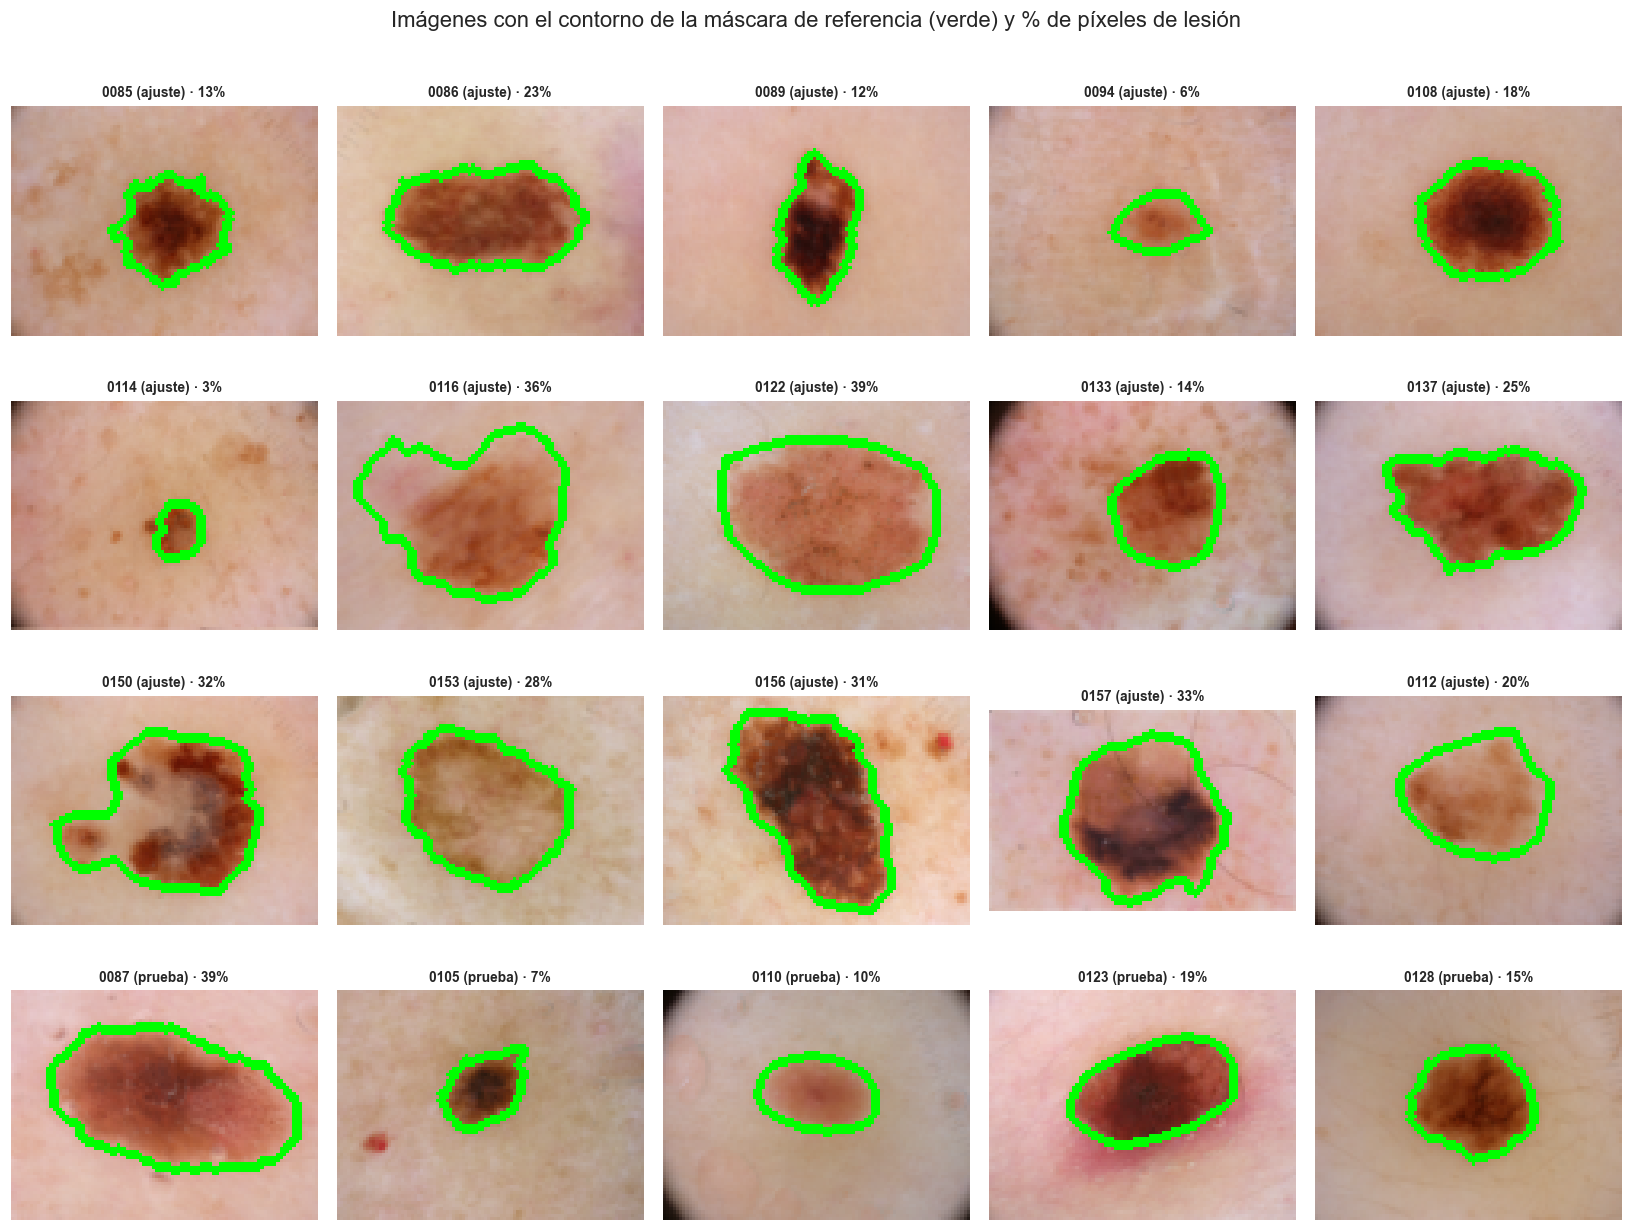

In [4]:
def contorno(m):
    return m.astype(bool) ^ ndi.binary_erosion(m.astype(bool))

fig, axs = plt.subplots(4, 5, figsize=(15, 11.5))
for ax, _id in zip(axs.ravel(), IDS_AJUSTE + IDS_PRUEBA):
    vis = imagenes[_id].copy()
    vis[ndi.binary_dilation(contorno(mascaras[_id]))] = [0, 255, 0]
    ax.imshow(vis); ax.axis('off')
    ax.set_title(f"{_id[-4:]} ({'ajuste' if _id in IDS_AJUSTE else 'prueba'}) · {mascaras[_id].mean()*100:.0f}%", fontsize=9)
fig.suptitle('Imágenes con el contorno de la máscara de referencia (verde) y % de píxeles de lesión', y=1.0)
plt.tight_layout(); plt.show()

> **Observaciones sobre los datos.**
> * **Tamaño y resolución:** casi todas las imágenes originales miden 2048×1536 (algunas 2592×1944 y una de 963×629); se trabaja a lado mayor = 96 px.
> * **Proporción de lesión:** varía entre 3,1 % (ISIC_0000114) y 38,9 % (ISIC_0000122); media de 22,3 % en ajuste y 18,0 % en prueba. Hay clases muy desbalanceadas a nivel de píxel, por eso se usa Dice y no *accuracy*.
> * **Contraste:** hay lesiones oscuras y bien delimitadas (0085, 0108, 0128) y lesiones pálidas o difusas, de bajo contraste con la piel (0094, 0110, 0112, 0153).
> * **Artefactos:** viñeteado con esquinas negras del dermatoscopio (0133, 0112, 0110), vello (0157, 0128), puntos rojos (0105, 0156) y enrojecimiento alrededor de la lesión (0123).
> * Las máscaras de referencia incluyen con frecuencia la zona de transición de la lesión, que puede ser de color casi igual al de la piel (0116, 0150).

<a name="s2"></a>
## 2. Pipeline de preparación y representación

Cada imagen se representa como una matriz con **un píxel por fila** y las características **[β·R, β·G, β·B, λ·x, λ·y]**, con color y coordenadas normalizados en [0, 1]. β y λ son parámetros del transformador, modificables sin cambiar la implementación.

In [5]:
class RepresentacionPixel(BaseEstimator, TransformerMixin):
    """Convierte una imagen (H, W, 3) en una matriz (H*W, 5): [β·R, β·G, β·B, λ·x, λ·y].
    Color y coordenadas se normalizan a [0, 1]; β y λ ponderan color y posición."""

    def __init__(self, beta=1.0, lam=1.0):
        self.beta = beta
        self.lam = lam

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        img = np.asarray(X, dtype=float) / 255.0            # color en [0, 1]
        h, w, _ = img.shape
        yy, xx = np.mgrid[0:h, 0:w]
        x = xx.ravel() / (w - 1)                             # coordenadas en [0, 1]
        y = yy.ravel() / (h - 1)
        return np.column_stack([self.beta * img.reshape(-1, 3), self.lam * x, self.lam * y])

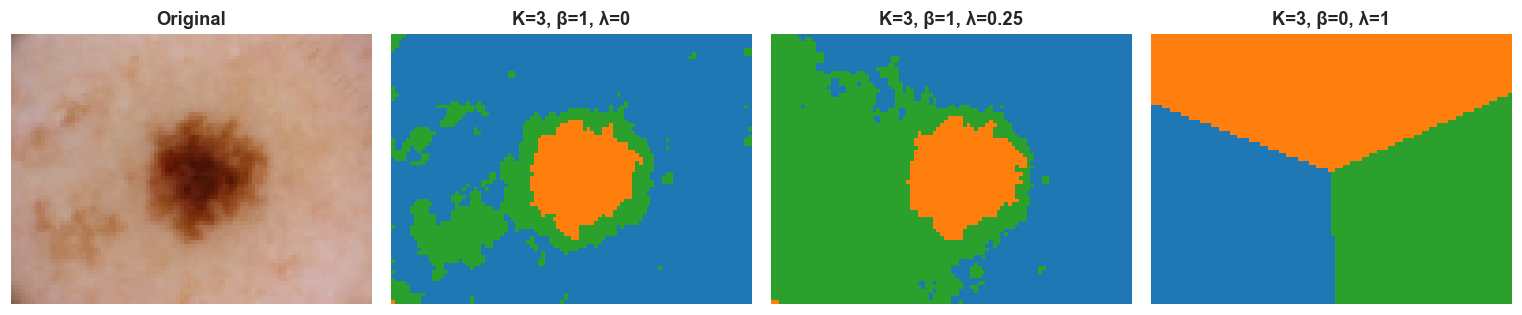

In [6]:
pipeline = Pipeline([
    ('representacion', RepresentacionPixel(beta=1.0, lam=1.0)),
    ('kmeans', KMeans(n_clusters=3, n_init=N_INIT, random_state=RANDOM_STATE)),
])

# β y λ se modifican sin tocar la implementación: set_params sobre el pipeline
img_demo = imagenes['ISIC_0000085']
fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))
axs[0].imshow(img_demo); axs[0].set_title('Original')
for ax, (b, l) in zip(axs[1:], [(1, 0), (1, 0.25), (0, 1)]):
    pipeline.set_params(representacion__beta=b, representacion__lam=l).fit(img_demo)
    ax.imshow(pipeline['kmeans'].labels_.reshape(img_demo.shape[:2]), cmap='tab10', vmin=0, vmax=9)
    ax.set_title(f'K=3, β={b}, λ={l}')
for ax in axs: ax.axis('off')
plt.tight_layout(); plt.show()

In [7]:
# Pruebas de cordura de la representación
X11 = RepresentacionPixel(1, 1).transform(img_demo)
h, w, _ = img_demo.shape
print('forma de salida:', X11.shape, '= (H*W, 5) =', (h * w, 5))
print('mínimos por columna:', X11.min(0).round(3), '| máximos:', X11.max(0).round(3))
assert X11.shape == (h * w, 5) and X11.min() >= 0 and X11.max() <= 1

solo_pos = RepresentacionPixel(beta=0, lam=1).transform(img_demo)
solo_col = RepresentacionPixel(beta=1, lam=0).transform(img_demo)
print('β = 0  -> columnas de color nulas  :', bool(np.all(solo_pos[:, :3] == 0)))
print('λ = 0  -> columnas de posición nulas:', bool(np.all(solo_col[:, 3:] == 0)))

# La razón λ/β es lo único que importa: (1, 0.5) y (2, 1) dan los mismos grupos
g1 = KMeans(3, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(RepresentacionPixel(1, 0.5).transform(img_demo))
g2 = KMeans(3, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(RepresentacionPixel(2, 1).transform(img_demo))
print('(β=1, λ=0,5) y (β=2, λ=1) producen los mismos grupos:', bool(np.array_equal(g1, g2)))

# La matriz permite reconstruir la imagen (R,G,B en las 3 primeras columnas)
rec = np.rint(X11[:, :3].reshape(h, w, 3) * 255).astype(np.uint8)
print('reconstrucción exacta de la imagen:', bool(np.array_equal(rec, img_demo)))

forma de salida: (6912, 5) = (H*W, 5) = (6912, 5)
mínimos por columna: [0.263 0.063 0.012 0.    0.   ] | máximos: [0.835 0.702 0.694 1.    1.   ]
β = 0  -> columnas de color nulas  : True
λ = 0  -> columnas de posición nulas: True
(β=1, λ=0,5) y (β=2, λ=1) producen los mismos grupos: True
reconstrucción exacta de la imagen: True


> **Justificación.** Color y coordenadas se normalizan a [0, 1] para que, con β = λ = 1, ambos bloques de características contribuyan a la distancia euclidiana en la misma escala; si las coordenadas estuvieran en píxeles (0–95) dominarían por completo al color. β y λ son hiperparámetros del transformador (no del código) para poder explorarlos con `set_params` dentro del `Pipeline`. Los casos extremos se verifican arriba: β = 0 deja solo la posición (los grupos son bloques espaciales que ignoran la imagen) y λ = 0 solo el color (los grupos son regiones de color similar sin importar dónde estén). También se comprobó que (β=1, λ=0,5) y (β=2, λ=1) producen los mismos grupos: solo importa la razón λ/β.

<a name="s3"></a>
## 3. Agrupación y selección de K

Para cada imagen de ajuste se exploran **diez combinaciones de (β, λ)** con razones λ/β distintas (incluyendo solo color y solo posición). Para cada combinación se aplica K-medias con K ∈ {2, …, 8} y se elige K por **coeficiente de silueta** sobre una **muestra reproducible de píxeles**.

> **Recordatorio.** K-medias depende de las distancias relativas: (β=1, λ=0,5) y (β=2, λ=1) producen los mismos grupos. Lo que importa es la razón λ/β.

In [8]:
# 10 combinaciones con razones λ/β distintas, incluyendo solo color (λ=0) y solo posición (β=0)
COMBINACIONES = [(1, 0), (1, 0.05), (1, 0.1), (1, 0.25), (1, 0.5), (1, 0.75), (1, 1), (1, 2), (1, 4), (0, 1)]

def nombre_comb(b, l):
    if l == 0: return 'solo color'
    if b == 0: return 'solo posición'
    return f'λ/β={l / b:g}'

pd.DataFrame([{'β': b, 'λ': l, 'λ/β': (l / b if b else np.inf), 'nombre': nombre_comb(b, l)} for b, l in COMBINACIONES])

,β,λ,λ/β,nombre
0,1,0.00,0.00,solo color
1,1,0.05,0.05,λ/β=0.05
2,1,0.10,0.10,λ/β=0.1
3,1,0.25,0.25,λ/β=0.25
4,1,0.50,0.50,λ/β=0.5
5,1,0.75,0.75,λ/β=0.75
6,1,1.00,1.00,λ/β=1
7,1,2.00,2.00,λ/β=2
8,1,4.00,4.00,λ/β=4
9,0,1.00,inf,solo posición


In [9]:
def seleccionar_k(img, beta, lam, k_rango=K_RANGO, n_muestra=N_MUESTRA_SIL, semilla=RANDOM_STATE):
    """Ajusta K-medias para cada K, calcula la silueta sobre una muestra fija y reproducible de píxeles
    (la misma para todos los K) y devuelve el K con mayor silueta junto con las etiquetas de cada K."""
    pipe = Pipeline([('representacion', RepresentacionPixel(beta, lam)),
                     ('kmeans', KMeans(n_clusters=2, n_init=N_INIT, random_state=semilla))])
    X = pipe['representacion'].transform(img)
    idx = np.random.RandomState(semilla).choice(len(X), min(n_muestra, len(X)), replace=False)
    sil, etiq = {}, {}
    for k in k_rango:
        pipe.set_params(kmeans__n_clusters=k).fit(img)
        lab = pipe['kmeans'].labels_
        etiq[k] = lab.reshape(img.shape[:2]).astype(np.int8)
        sil[k] = silhouette_score(X[idx], lab[idx]) if len(np.unique(lab[idx])) > 1 else -1.0
    k_opt = max(sil, key=sil.get)
    return {'k': k_opt, 'sil': sil[k_opt], 'sil_por_k': sil, 'etiquetas': etiq[k_opt], 'etiquetas_por_k': etiq}

In [10]:
AGRUPACIONES = {}   # (id, β, λ) -> resultado de seleccionar_k
t0 = time.time()
for _id in IDS_AJUSTE:
    for b, l in COMBINACIONES:
        AGRUPACIONES[(_id, b, l)] = seleccionar_k(imagenes[_id], b, l)
print(f'{len(AGRUPACIONES)} agrupaciones (15 imágenes × 10 combinaciones × 7 valores de K) '
      f'en {time.time() - t0:.0f} s | muestra de silueta = {N_MUESTRA_SIL} píxeles | semilla = {RANDOM_STATE}')

resultados_agrupacion = pd.DataFrame([
    {'id': i, 'beta': b, 'lam': l, 'combinacion': nombre_comb(b, l), 'k': r['k'], 'silueta': r['sil']}
    for (i, b, l), r in AGRUPACIONES.items()])
resultados_agrupacion.groupby('combinacion', sort=False).agg(
    k_medio=('k', 'mean'), silueta_media=('silueta', 'mean')).round(3)

150 agrupaciones (15 imágenes × 10 combinaciones × 7 valores de K) en 460 s | muestra de silueta = 3000 píxeles | semilla = 42


,k_medio,silueta_media
combinacion,,
solo color,2.000,0.754
λ/β=0.05,2.000,0.743
λ/β=0.1,2.000,0.720
λ/β=0.25,2.200,0.618
λ/β=0.5,3.200,0.494
λ/β=0.75,4.933,0.444
λ/β=1,5.000,0.443
λ/β=2,4.933,0.427
λ/β=4,4.667,0.404


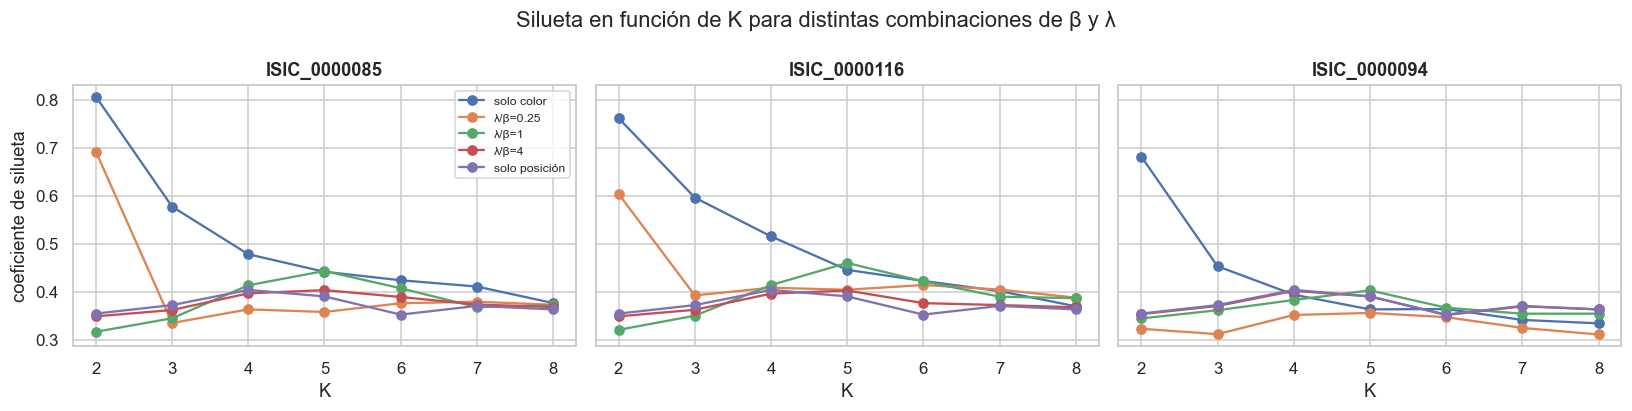

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, _id in zip(axs, ['ISIC_0000085', 'ISIC_0000116', 'ISIC_0000094']):
    for b, l in [(1, 0), (1, 0.25), (1, 1), (1, 4), (0, 1)]:
        s = AGRUPACIONES[(_id, b, l)]['sil_por_k']
        ax.plot(list(s), list(s.values()), marker='o', label=nombre_comb(b, l))
    ax.set_title(_id); ax.set_xlabel('K')
axs[0].set_ylabel('coeficiente de silueta'); axs[0].legend(fontsize=8)
plt.suptitle('Silueta en función de K para distintas combinaciones de β y λ'); plt.tight_layout(); plt.show()

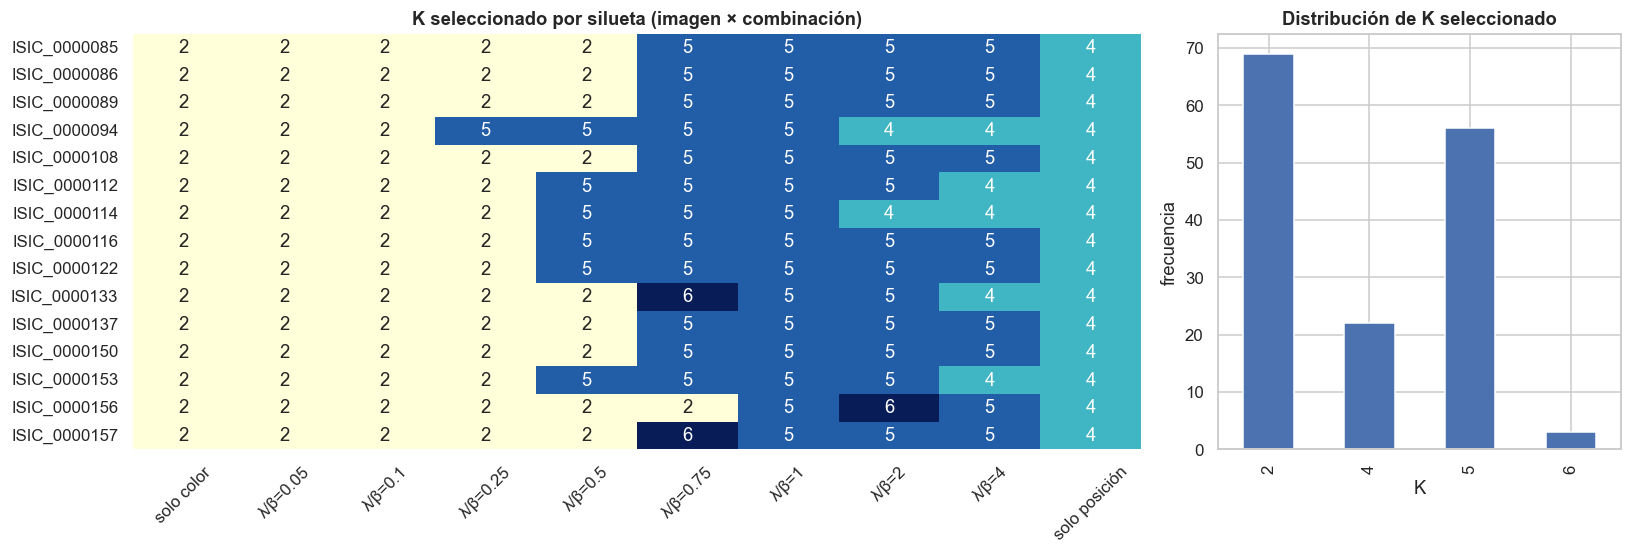

In [12]:
tabla_k = resultados_agrupacion.pivot(index='id', columns='combinacion', values='k')[[nombre_comb(b, l) for b, l in COMBINACIONES]]
fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [3, 1.2]})
sns.heatmap(tabla_k, annot=True, cmap='YlGnBu', cbar=False, ax=axs[0])
axs[0].set_title('K seleccionado por silueta (imagen × combinación)'); axs[0].set_xlabel(''); axs[0].set_ylabel('')
axs[0].tick_params(axis='x', rotation=45)
resultados_agrupacion['k'].value_counts().sort_index().plot.bar(ax=axs[1], color='#4c72b0')
axs[1].set_title('Distribución de K seleccionado'); axs[1].set_xlabel('K'); axs[1].set_ylabel('frecuencia')
plt.tight_layout(); plt.show()

> **Análisis.** La silueta se calcula sobre una muestra fija de **3 000 píxeles** (≈43 % de los 6 912 de cada imagen), extraída con **semilla 42**; es la misma muestra para todos los valores de K de una imagen y combinación, de modo que las siluetas son comparables y el resultado es reproducible.
>
> Con λ/β ≤ 0,1 se selecciona **K = 2** en las 15 imágenes (silueta media de 0,754 con solo color): el color separa muy bien lesión y piel. Al aumentar el peso de la posición, K sube (K medio 2,2 con λ/β = 0,25; 3,2 con 0,5; ≈4,9 con λ/β ≥ 0,75) y la silueta cae hasta ≈0,40: la posición, que varía de forma continua en toda la imagen, fragmenta la piel en bloques espaciales. Con solo posición K = 4 (cuatro cuadrantes) y la silueta es 0,404. La silueta alta de K = 2 indica grupos compactos y separados, no necesariamente la lesión; esto se retoma en la sección 7.2.

<a name="s4"></a>
## 4. Construcción de la máscara de la lesión

K-medias agrupa píxeles pero no dice cuáles son la lesión. Se diseña un **criterio automático**, que **no use las máscaras de referencia**, basado en las características de los grupos (color, tamaño, ubicación, etc.). Se comparan al menos dos criterios.

In [13]:
def _color_piel(img, fraccion=0.1):
    """Color de la piel sana: mediana de un marco (10 %) en el borde de la imagen."""
    h, w, _ = img.shape
    a, b = max(1, int(h * fraccion)), max(1, int(w * fraccion))
    marco = np.zeros((h, w), bool)
    marco[:a] = marco[-a:] = True
    marco[:, :b] = marco[:, -b:] = True
    return np.median(img[marco].reshape(-1, 3), axis=0)

def _componente_principal(mascara):
    """Se queda con la componente conexa más grande y rellena sus huecos."""
    lab, n = ndi.label(mascara)
    if n == 0:
        return mascara
    tam = ndi.sum(mascara, lab, range(1, n + 1))
    return ndi.binary_fill_holes(lab == 1 + np.argmax(tam))

def mascara_criterio_a(img, etiquetas):
    """Criterio A: la lesión es el grupo con el color medio más oscuro (menor luminosidad media)."""
    gris = img.astype(float).mean(axis=2)
    ks = np.unique(etiquetas)
    k_lesion = ks[np.argmin([gris[etiquetas == k].mean() for k in ks])]
    return (etiquetas == k_lesion).astype(np.uint8)

def mascara_criterio_b(img, etiquetas, umbral=0.5):
    """Criterio B: la lesión son los grupos cuyo color medio se aleja de la piel (marco de la imagen).
    Se seleccionan los grupos con distancia >= umbral × la distancia máxima, y se conserva la componente
    conexa principal con los huecos rellenos (elimina vello y manchas sueltas)."""
    x = img.reshape(-1, 3).astype(float)
    dist = np.linalg.norm(x - _color_piel(img), axis=1)
    lab = etiquetas.ravel()
    ks = np.unique(lab)
    d = np.array([dist[lab == k].mean() for k in ks])
    elegidos = ks[d >= umbral * d.max()]
    return _componente_principal(np.isin(etiquetas, elegidos)).astype(np.uint8)

CRITERIOS = {'A': mascara_criterio_a, 'B': mascara_criterio_b}

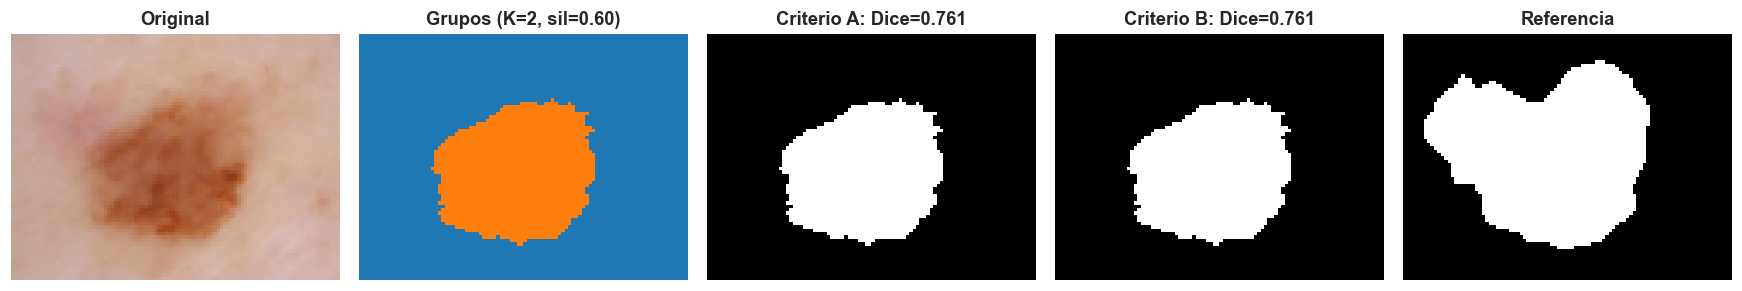

In [14]:
_id = 'ISIC_0000116'   # imagen de ajuste con una lesión grande y heterogénea
r = AGRUPACIONES[(_id, 1, 0.25)]
img, ref = imagenes[_id], mascaras[_id]
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6))
axs[0].imshow(img); axs[0].set_title('Original')
axs[1].imshow(r['etiquetas'], cmap='tab10', vmin=0, vmax=9); axs[1].set_title(f"Grupos (K={r['k']}, sil={r['sil']:.2f})")
for ax, c in zip(axs[2:4], 'AB'):
    est = CRITERIOS[c](img, r['etiquetas'])
    ax.imshow(est, cmap='gray'); ax.set_title(f'Criterio {c}: Dice={f1_score(ref.ravel(), est.ravel()):.3f}')
axs[4].imshow(ref, cmap='gray'); axs[4].set_title('Referencia')
for ax in axs: ax.axis('off')
plt.tight_layout(); plt.show()

> **Justificación de los criterios.** Ninguno usa las máscaras de referencia; solo el color y la ubicación de los grupos.
>
> * **Criterio A (grupo más oscuro).** Hipótesis: la lesión pigmentada es más oscura que la piel. Es simple, pero se rompe cuando (i) el viñeteado deja esquinas negras que forman un grupo más oscuro que la lesión (0133, 0112, 0110) y (ii) K > 2 parte la lesión en un núcleo oscuro y una periferia más clara, de la que solo se conserva el núcleo (bajo recall).
> * **Criterio B (distancia al color de piel + conectividad).** Se estima el color de la piel como la mediana del marco del 10 % exterior, se calcula la distancia media de cada grupo a ese color y se toman los grupos con distancia ≥ 0,5 × la distancia máxima; luego se conserva la **componente conexa más grande** y se **rellenan sus huecos**. Así puede unir varios grupos de la lesión (núcleo y periferia), no depende de que la lesión sea el grupo más oscuro, y descarta las esquinas del viñeteado y las manchas aisladas por no estar conectadas a la lesión. El umbral de 0,5 se fijó mirando solo imágenes de ajuste y resultó insensible (0,3–0,7 dieron el mismo resultado).
>
> **Evidencia (ver sección 5):** con solo color el Dice medio es 0,8505 con A (mínimo 0,596) y 0,8878 con B (mínimo 0,761). B supera a A en las 5 combinaciones que usan color con λ/β ≤ 0,5.

<a name="s5"></a>
## 5. Ajuste del método (solo imágenes de ajuste)

Se evalúan las 10 combinaciones (β, λ) × los criterios de máscara sobre las **15 imágenes de ajuste**. Métrica principal: **Dice promedio**; complementaria: **V-measure**.

$$DICE = \frac{2|X \cap Y|}{|X| + |Y|}$$

In [15]:
def dice(mascara_ref, mascara_est):
    """Dice = F1 a nivel de píxel con la lesión como clase positiva."""
    return f1_score(mascara_ref.ravel(), mascara_est.ravel(), zero_division=0)

def v_measure(mascara_ref, etiquetas):
    """V-measure entre los grupos de K-medias y las etiquetas de referencia."""
    return v_measure_score(mascara_ref.ravel(), etiquetas.ravel())

def evaluar(img, ref, etiquetas, criterio):
    """Construye la máscara con el criterio dado y devuelve (máscara, métricas)."""
    est = CRITERIOS[criterio](img, etiquetas)
    y, p = ref.ravel(), est.ravel()
    return est, {'dice': dice(ref, est), 'vmeasure': v_measure(ref, etiquetas),
                 'precision': precision_score(y, p, zero_division=0), 'recall': recall_score(y, p, zero_division=0)}

In [16]:
filas = []
for (_id, b, l), r in AGRUPACIONES.items():
    for c in CRITERIOS:
        _, m = evaluar(imagenes[_id], mascaras[_id], r['etiquetas'], c)
        filas.append({'id': _id, 'beta': b, 'lam': l, 'combinacion': nombre_comb(b, l),
                      'criterio': c, 'k': r['k'], 'silueta': r['sil'], **m})
metricas_ajuste = pd.DataFrame(filas)
print(metricas_ajuste.shape)
metricas_ajuste.head()

(300, 11)


,id,beta,lam,combinacion,criterio,k,silueta,dice,vmeasure,precision,recall
0,ISIC_0000085,1,0.00,solo color,A,2,0.806404,0.901373,0.758992,0.993122,0.825143
1,ISIC_0000085,1,0.00,solo color,B,2,0.806404,0.904195,0.758992,1.000000,0.825143
2,ISIC_0000085,1,0.05,λ/β=0.05,A,2,0.797422,0.901373,0.758992,0.993122,0.825143
3,ISIC_0000085,1,0.05,λ/β=0.05,B,2,0.797422,0.904195,0.758992,1.000000,0.825143
4,ISIC_0000085,1,0.10,λ/β=0.1,A,2,0.777164,0.901373,0.758992,0.993122,0.825143


In [17]:
resumen = (metricas_ajuste.groupby(['beta', 'lam', 'combinacion', 'criterio'])
           .agg(dice_medio=('dice', 'mean'), dice_std=('dice', 'std'), dice_min=('dice', 'min'),
                vmeasure_medio=('vmeasure', 'mean'), k_medio=('k', 'mean'), silueta_media=('silueta', 'mean'))
           .reset_index().sort_values('dice_medio', ascending=False).reset_index(drop=True))
resumen.index += 1
display(resumen.round(4))
print('Dos mejores configuraciones por Dice promedio:')
display(resumen.head(2).round(4))

,beta,lam,combinacion,criterio,dice_medio,dice_std,dice_min,vmeasure_medio,k_medio,silueta_media
1,1,0.25,λ/β=0.25,B,0.8903,0.0651,0.7611,0.6155,2.2000,0.6177
2,1,0.05,λ/β=0.05,B,0.8879,0.0634,0.7608,0.6482,2.0000,0.7435
3,1,0.00,solo color,B,0.8878,0.0635,0.7608,0.6481,2.0000,0.7538
4,1,0.10,λ/β=0.1,B,0.8872,0.0632,0.7611,0.6466,2.0000,0.7201
5,1,0.50,λ/β=0.5,B,0.8844,0.0661,0.7455,0.5286,3.2000,0.4940
6,1,0.75,λ/β=0.75,B,0.8730,0.0684,0.7359,0.3313,4.9333,0.4437
7,1,0.50,λ/β=0.5,A,0.8609,0.0758,0.7441,0.5286,3.2000,0.4940
8,1,0.25,λ/β=0.25,A,0.8548,0.1039,0.5860,0.6155,2.2000,0.6177
9,1,0.05,λ/β=0.05,A,0.8506,0.1001,0.5956,0.6482,2.0000,0.7435
10,1,0.00,solo color,A,0.8505,0.1001,0.5956,0.6481,2.0000,0.7538


Dos mejores configuraciones por Dice promedio:


,beta,lam,combinacion,criterio,dice_medio,dice_std,dice_min,vmeasure_medio,k_medio,silueta_media
1,1,0.25,λ/β=0.25,B,0.8903,0.0651,0.7611,0.6155,2.2,0.6177
2,1,0.05,λ/β=0.05,B,0.8879,0.0634,0.7608,0.6482,2.0,0.7435


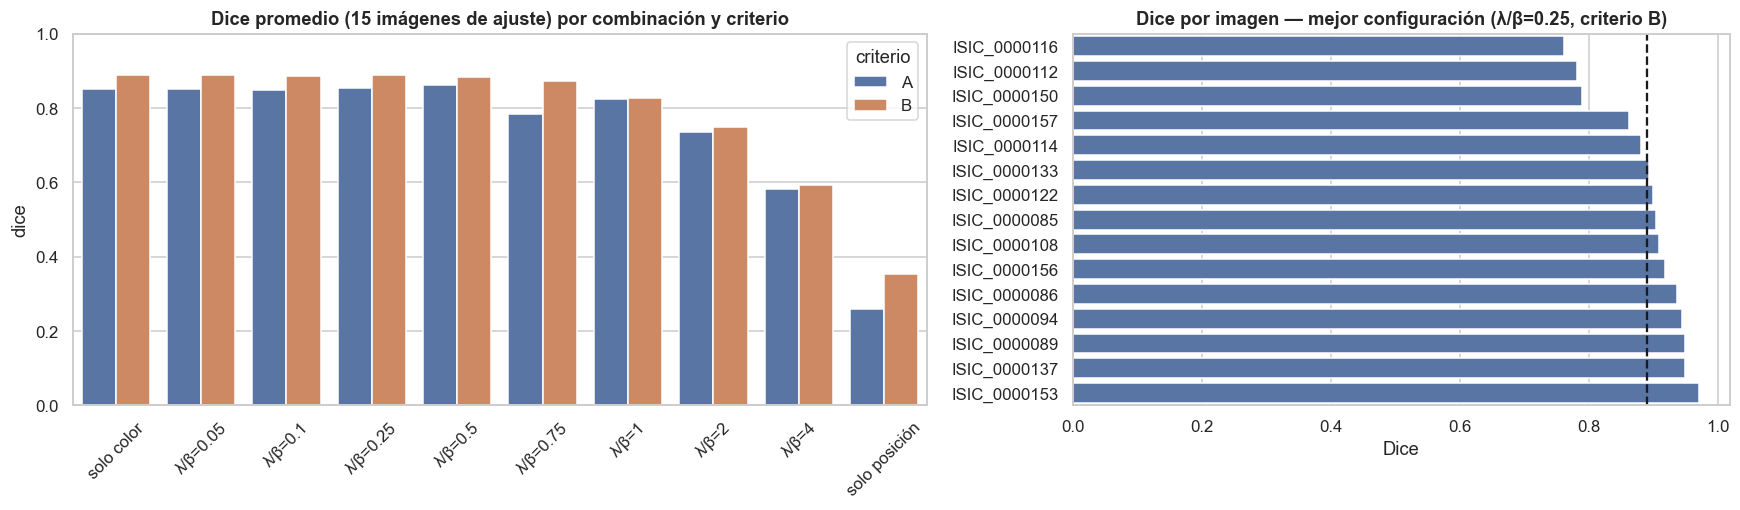

In [18]:
orden = [nombre_comb(b, l) for b, l in COMBINACIONES]
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
sns.barplot(data=metricas_ajuste, x='combinacion', y='dice', hue='criterio', order=orden, errorbar=None, ax=axs[0])
axs[0].set_title('Dice promedio (15 imágenes de ajuste) por combinación y criterio')
axs[0].set_xlabel(''); axs[0].tick_params(axis='x', rotation=45); axs[0].set_ylim(0, 1)
top = resumen.iloc[0]
sub = metricas_ajuste[(metricas_ajuste.beta == top.beta) & (metricas_ajuste.lam == top.lam) & (metricas_ajuste.criterio == top.criterio)]
sns.barplot(data=sub.sort_values('dice'), y='id', x='dice', color='#4c72b0', ax=axs[1])
axs[1].set_title(f'Dice por imagen — mejor configuración ({top.combinacion}, criterio {top.criterio})')
axs[1].axvline(sub.dice.mean(), color='k', ls='--'); axs[1].set_xlabel('Dice'); axs[1].set_ylabel('')
plt.tight_layout(); plt.show()

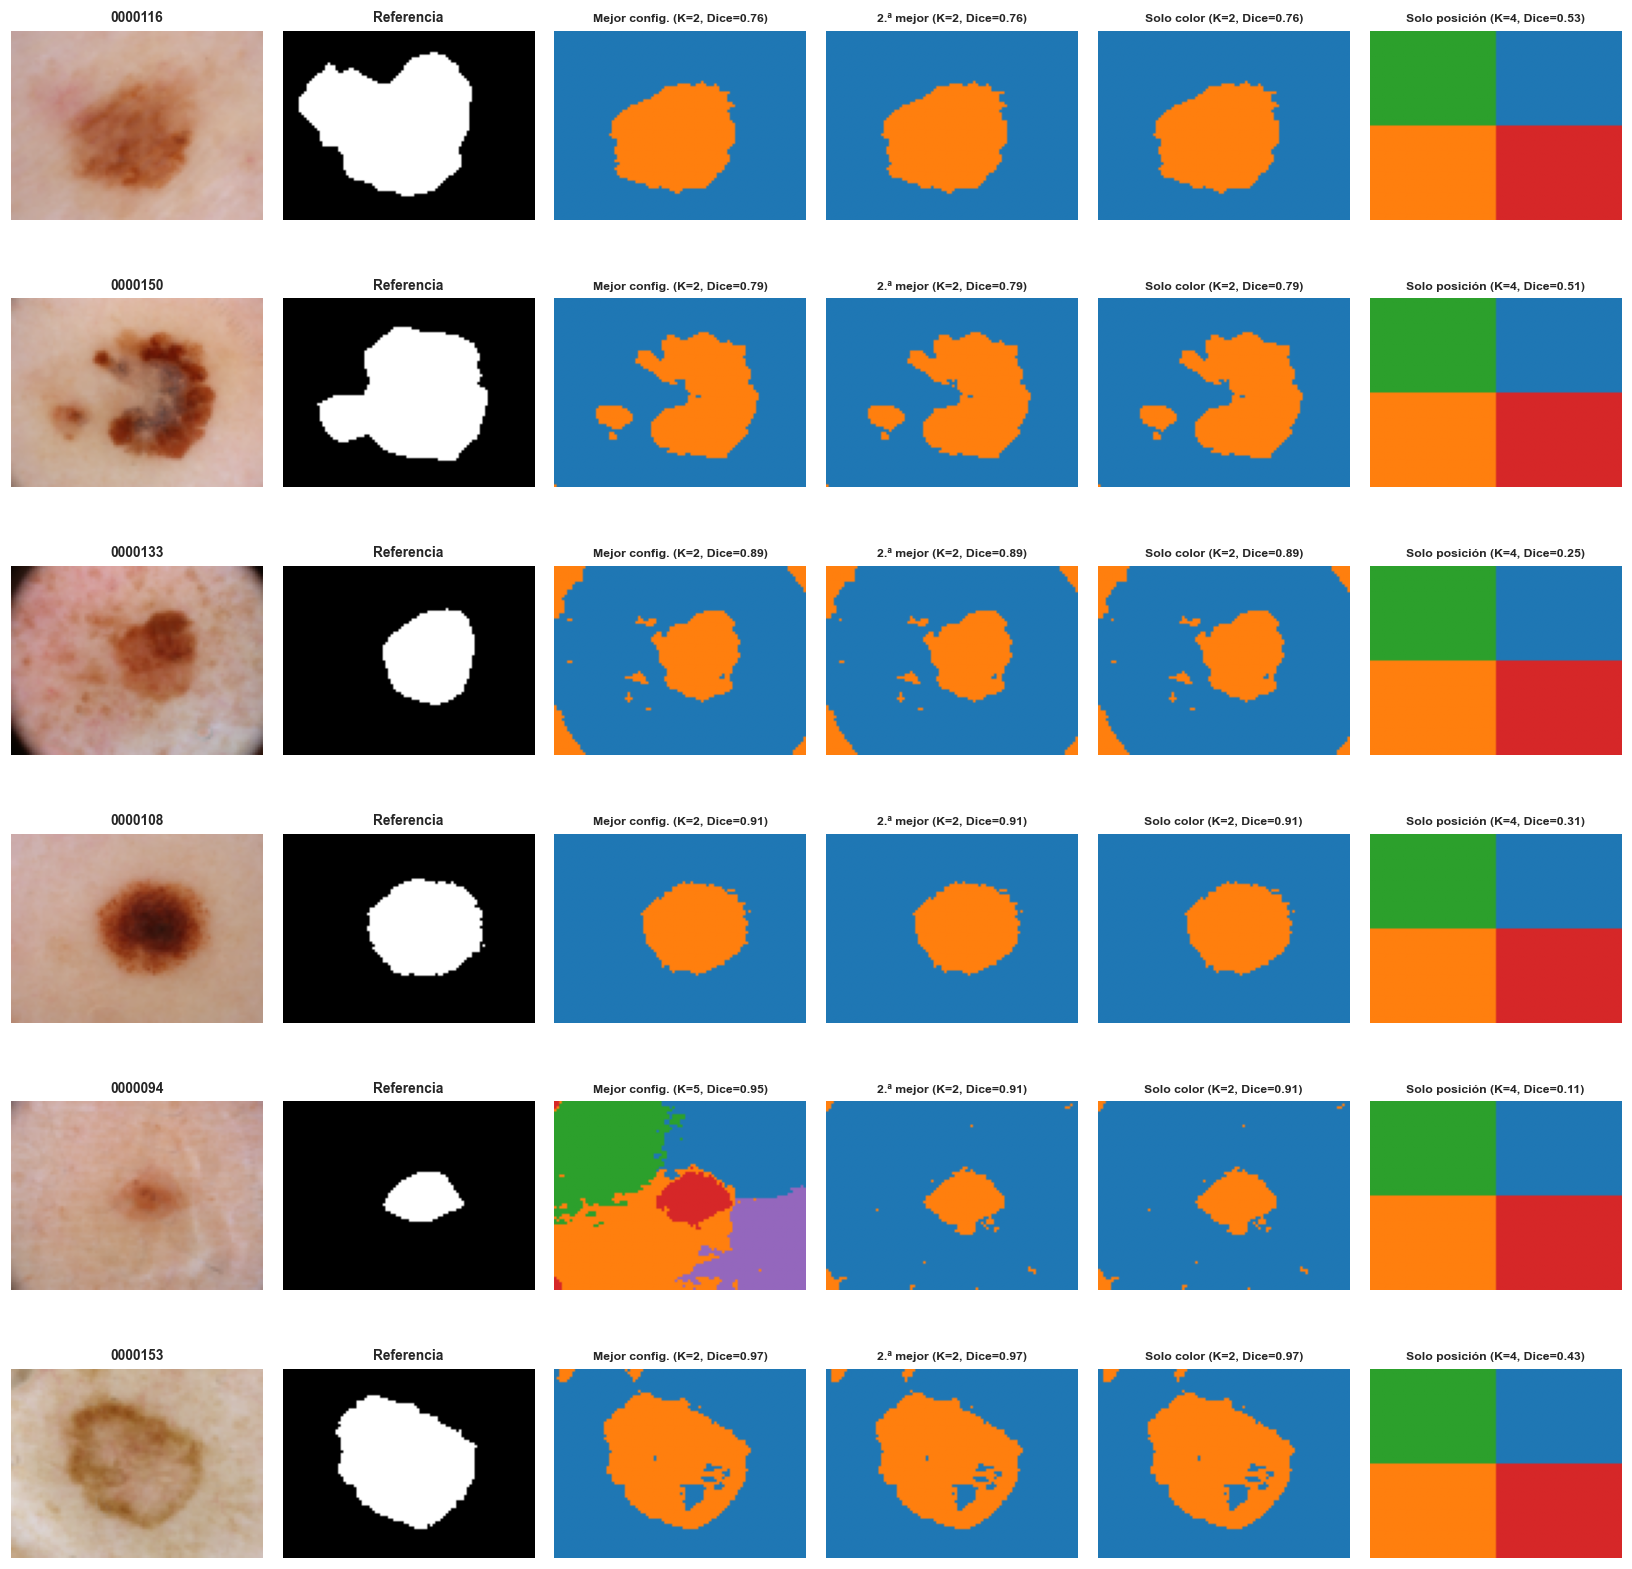

In [19]:
def fila_resumen(b, l, c=None):
    s = resumen[(resumen.beta == b) & (resumen.lam == l)]
    if c: s = s[s.criterio == c]
    return s.iloc[0]

mejor1, mejor2 = resumen.iloc[0], resumen.iloc[1]
solo_color, solo_pos = fila_resumen(1, 0), fila_resumen(0, 1)
vistas = [('Mejor config.', mejor1), ('2.ª mejor', mejor2), ('Solo color', solo_color), ('Solo posición', solo_pos)]

# 6 imágenes representativas, ordenadas por Dice de la mejor configuración
d1 = metricas_ajuste[(metricas_ajuste.beta == mejor1.beta) & (metricas_ajuste.lam == mejor1.lam) &
                     (metricas_ajuste.criterio == mejor1.criterio)].set_index('id').dice.sort_values()
muestra = [d1.index[i] for i in np.linspace(0, len(d1) - 1, 6).astype(int)]

fig, axs = plt.subplots(len(muestra), 2 + len(vistas), figsize=(15, 2.5 * len(muestra)))
for fila, _id in enumerate(muestra):
    axs[fila, 0].imshow(imagenes[_id]); axs[fila, 0].set_title(_id[-7:], fontsize=9)
    axs[fila, 1].imshow(mascaras[_id], cmap='gray'); axs[fila, 1].set_title('Referencia', fontsize=9)
    for col, (nombre, cfg) in enumerate(vistas, start=2):
        r = AGRUPACIONES[(_id, cfg.beta, cfg.lam)]
        est, m = evaluar(imagenes[_id], mascaras[_id], r['etiquetas'], cfg.criterio)
        axs[fila, col].imshow(r['etiquetas'], cmap='tab10', vmin=0, vmax=9)
        axs[fila, col].set_title(f"{nombre} (K={r['k']}, Dice={m['dice']:.2f})", fontsize=8)
for ax in axs.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()

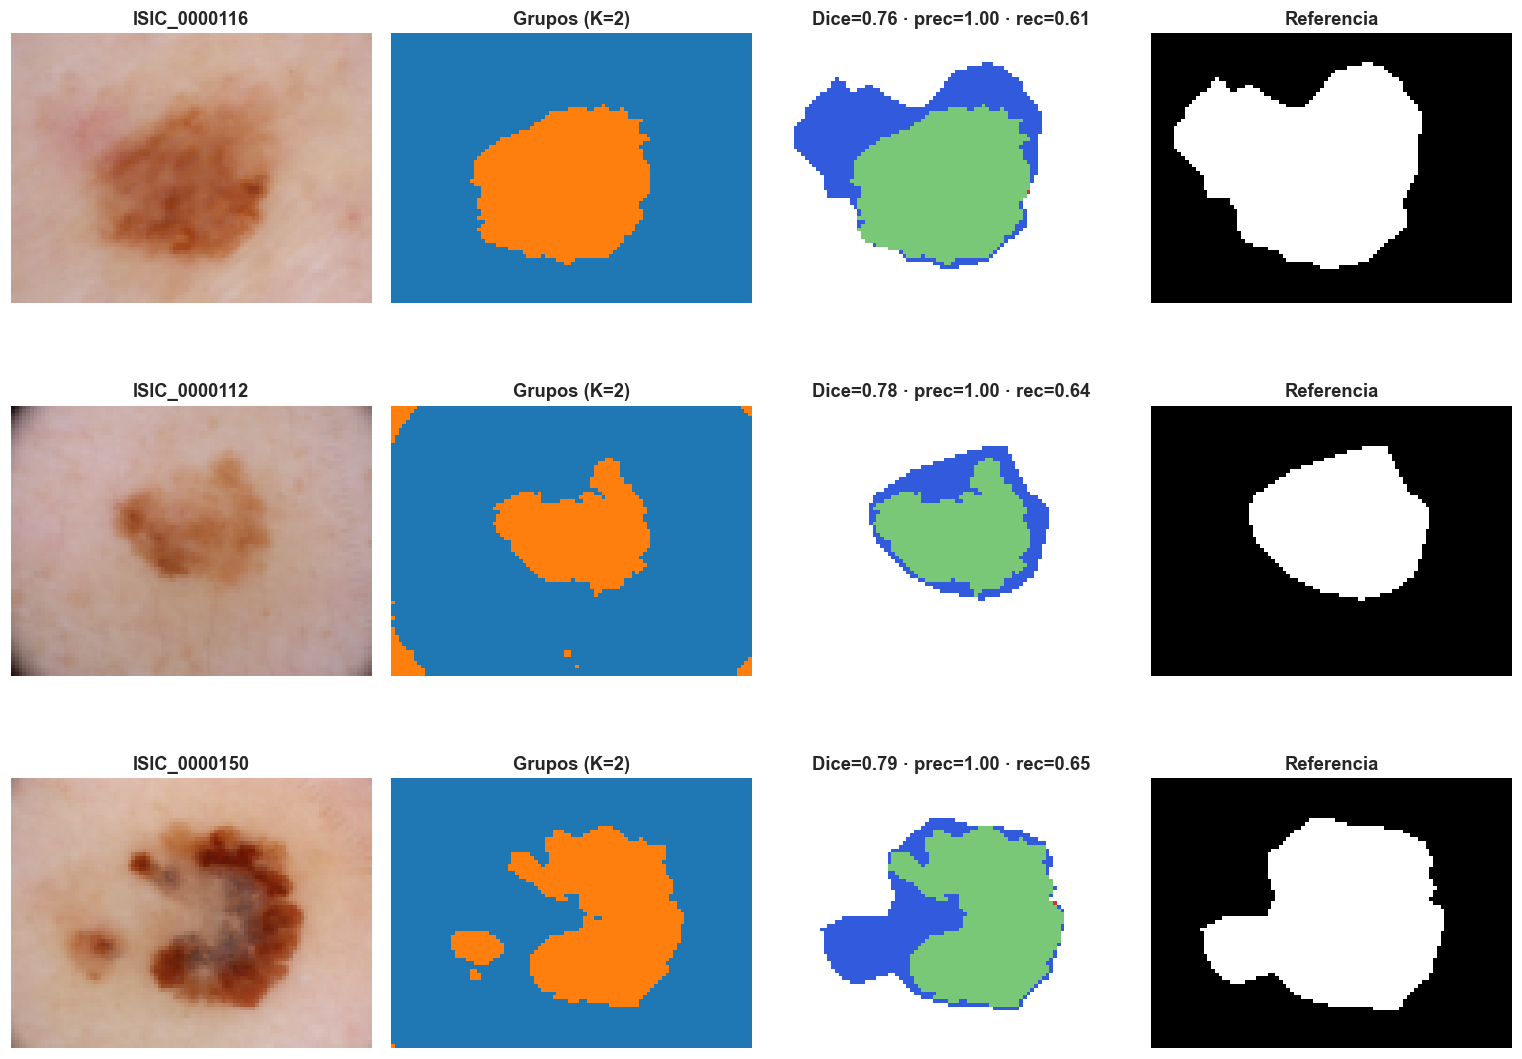

In [20]:
# Casos de fallo: las 3 imágenes con menor Dice en la mejor configuración
# (rojo = falso positivo, azul = falso negativo)
peores = d1.index[:3]
fig, axs = plt.subplots(len(peores), 4, figsize=(14, 3.6 * len(peores)))
for fila, _id in enumerate(peores):
    r = AGRUPACIONES[(_id, mejor1.beta, mejor1.lam)]
    est, m = evaluar(imagenes[_id], mascaras[_id], r['etiquetas'], mejor1.criterio)
    ref = mascaras[_id]
    err = np.zeros(ref.shape + (3,), np.uint8) + 255
    err[(ref == 1) & (est == 1)] = [120, 200, 120]
    err[(ref == 0) & (est == 1)] = [220, 50, 50]
    err[(ref == 1) & (est == 0)] = [50, 90, 220]
    axs[fila, 0].imshow(imagenes[_id]); axs[fila, 0].set_title(f"{_id}")
    axs[fila, 1].imshow(r['etiquetas'], cmap='tab10', vmin=0, vmax=9); axs[fila, 1].set_title(f"Grupos (K={r['k']})")
    axs[fila, 2].imshow(err); axs[fila, 2].set_title(f"Dice={m['dice']:.2f} · prec={m['precision']:.2f} · rec={m['recall']:.2f}")
    axs[fila, 3].imshow(ref, cmap='gray'); axs[fila, 3].set_title('Referencia')
for ax in axs.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()

In [21]:
# Configuración final: la de mayor Dice promedio en las imágenes de ajuste
CONFIG_FINAL = {'beta': float(mejor1.beta), 'lam': float(mejor1.lam), 'criterio': mejor1.criterio}
print('CONFIG_FINAL =', CONFIG_FINAL, '| Dice medio de ajuste =', round(mejor1.dice_medio, 4),
      '| V-measure medio =', round(mejor1.vmeasure_medio, 4))

CONFIG_FINAL = {'beta': 1.0, 'lam': 0.25, 'criterio': 'B'} | Dice medio de ajuste = 0.8903 | V-measure medio = 0.6155


### Configuración final

| Parámetro | Valor |
|:---|:---|
| β | 1 |
| λ | 0,25 (λ/β = 0,25) |
| Criterio de máscara | B (distancia al color de piel + componente conexa principal con huecos rellenos) |
| K | Seleccionado por silueta en cada imagen, K ∈ {2, …, 8} (muestra de 3 000 píxeles, semilla 42) |
| Dice promedio (ajuste) | 0,8903 (desv. 0,065; mínimo 0,761; máximo 0,971) |
| V-measure promedio (ajuste) | 0,6155 |

> **Justificación.** Es la configuración con mayor Dice medio entre las 20 evaluadas (10 combinaciones × 2 criterios). **Ser honestos con la diferencia:** las cuatro mejores configuraciones con criterio B (λ/β = 0, 0,05, 0,1 y 0,25) están separadas por menos de 0,004 de Dice, y la ventaja de λ/β = 0,25 sobre «solo color» (0,8878) se debe casi por completo a una imagen (ISIC_0000094: 0,907 → 0,945); en las demás el Dice cambia en menos de 0,002. Se mantiene como criterio de selección el Dice medio, tal como pide el enunciado, y se declara que no hay evidencia sólida de que una pequeña ponderación de la posición mejore sistemáticamente el método. El V-measure (0,6155) es *menor* que el de solo color (0,648), lo que confirma que una buena agrupación respecto a las etiquetas no es lo mismo que una buena máscara. Revisando los casos de fallo (0116, 0112, 0150) el error dominante son falsos negativos, no falsos positivos (precisión ≈ 1,00 y recall 0,61–0,65): el método se queda corto en la periferia pálida de la lesión.

<a name="s6"></a>
## 6. Evaluación sobre las imágenes de prueba

Se aplica la configuración final **sin modificaciones** a las 5 imágenes de prueba. Estas imágenes y sus máscaras se consultan aquí por primera vez.

In [22]:
# Se aplica CONFIG_FINAL sin ningún cambio: misma muestra y semilla para la silueta
filas, resultados_prueba = [], {}
for _id in IDS_PRUEBA:
    r = seleccionar_k(imagenes[_id], CONFIG_FINAL['beta'], CONFIG_FINAL['lam'])
    est, m = evaluar(imagenes[_id], mascaras[_id], r['etiquetas'], CONFIG_FINAL['criterio'])
    resultados_prueba[_id] = (r, est)
    filas.append({'id': _id, 'K': r['k'], 'silueta': r['sil'], 'Dice': m['dice'], 'V-measure': m['vmeasure'],
                  'precisión': m['precision'], 'recall': m['recall']})
metricas_prueba = pd.DataFrame(filas).set_index('id')
metricas_prueba.loc['PROMEDIO'] = metricas_prueba.mean()
metricas_prueba.round(4)

,K,silueta,Dice,V-measure,precisión,recall
id,,,,,,
ISIC_0000087,2.0,0.6350,0.8788,0.6354,1.0000,0.7838
ISIC_0000105,2.0,0.6927,0.9244,0.7590,1.0000,0.8595
ISIC_0000110,2.0,0.5836,0.7616,0.3257,1.0000,0.6150
ISIC_0000123,2.0,0.6662,0.8985,0.6959,0.8471,0.9566
ISIC_0000128,2.0,0.7011,0.9380,0.8294,1.0000,0.8832
PROMEDIO,2.0,0.6557,0.8803,0.6491,0.9694,0.8196


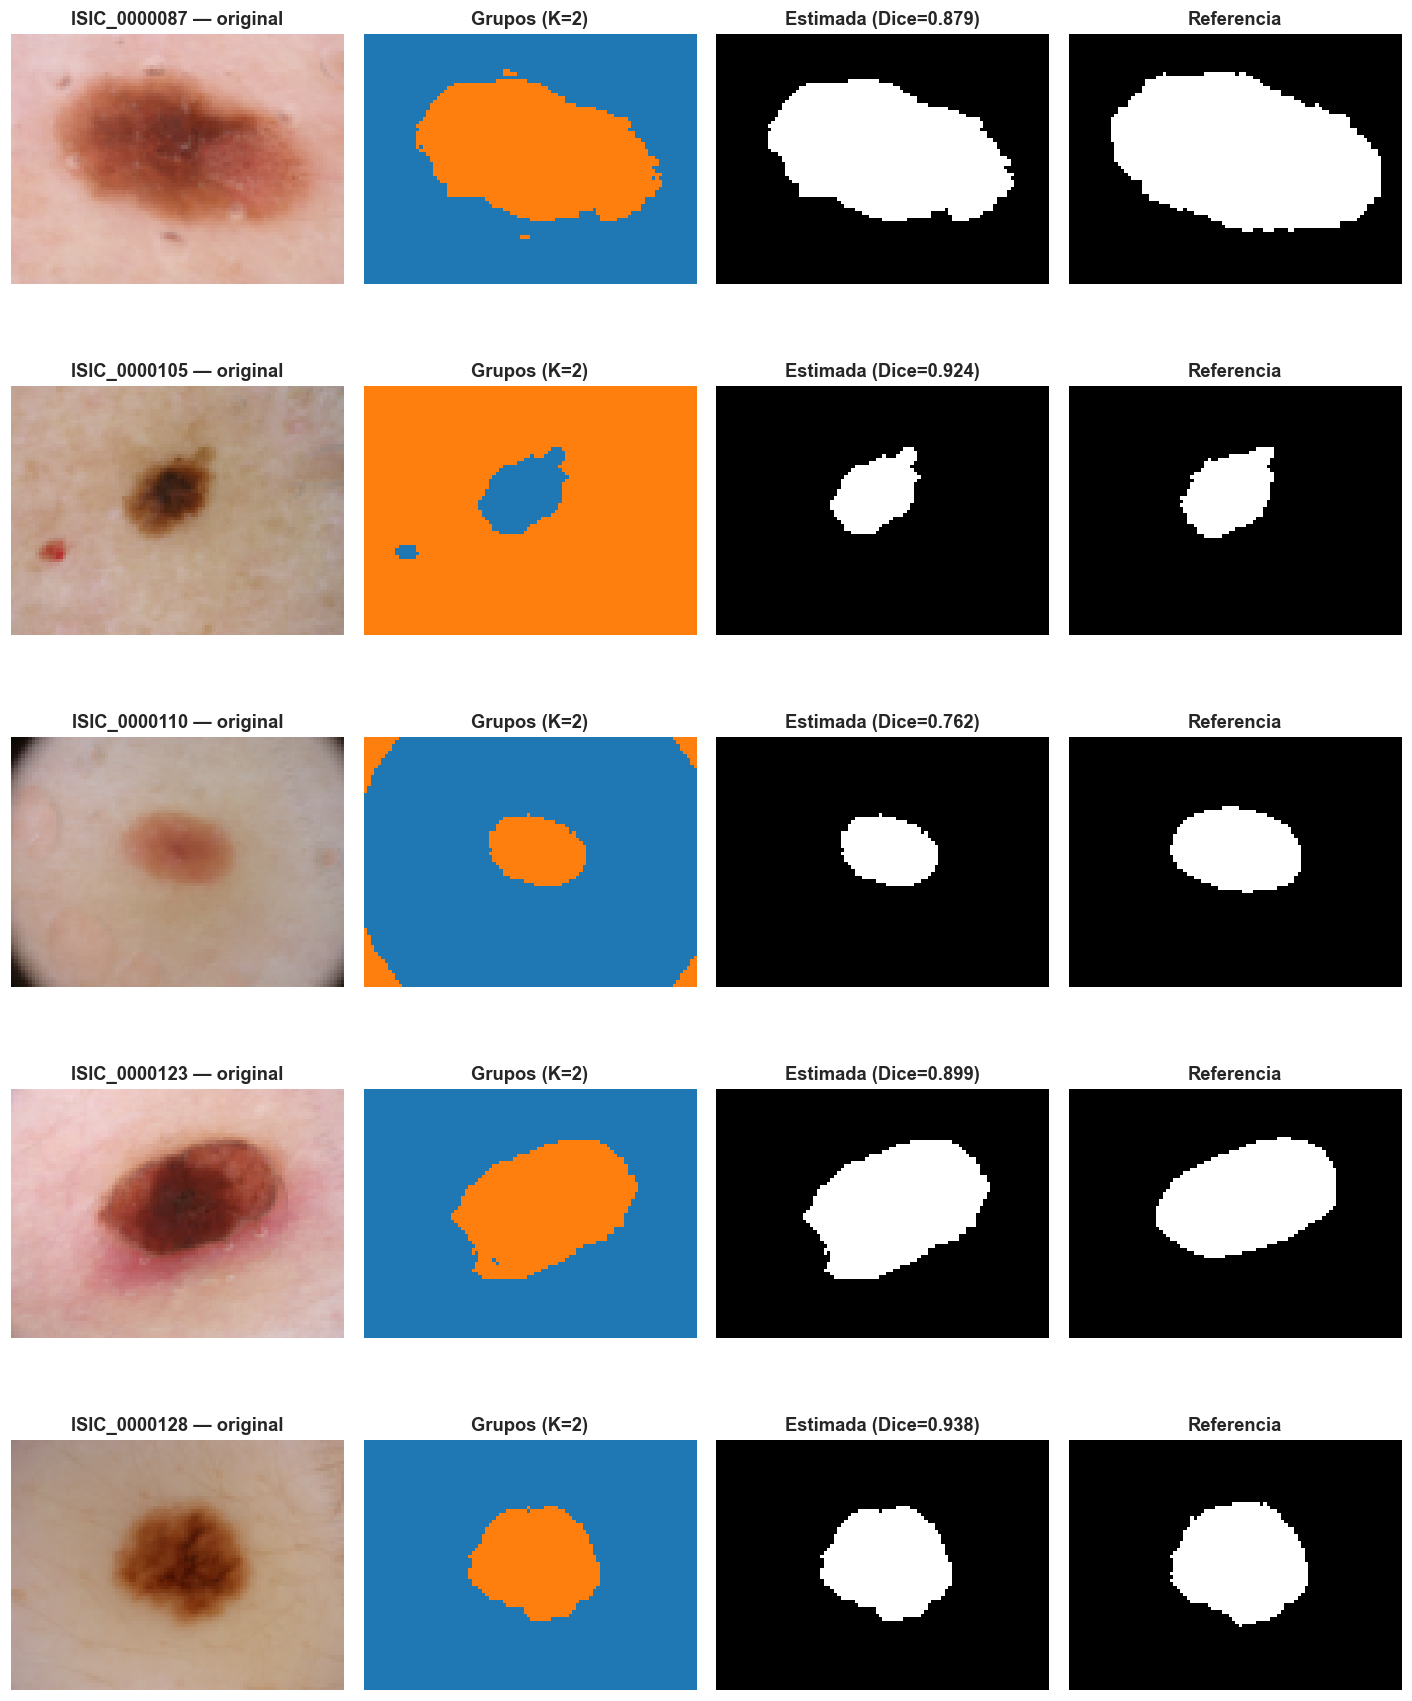

In [23]:
fig, axs = plt.subplots(len(IDS_PRUEBA), 4, figsize=(13, 3.3 * len(IDS_PRUEBA)))
for fila, _id in enumerate(IDS_PRUEBA):
    r, est = resultados_prueba[_id]
    axs[fila, 0].imshow(imagenes[_id]); axs[fila, 0].set_title(f'{_id} — original')
    axs[fila, 1].imshow(r['etiquetas'], cmap='tab10', vmin=0, vmax=9); axs[fila, 1].set_title(f"Grupos (K={r['k']})")
    axs[fila, 2].imshow(est, cmap='gray'); axs[fila, 2].set_title(f"Estimada (Dice={metricas_prueba.loc[_id, 'Dice']:.3f})")
    axs[fila, 3].imshow(mascaras[_id], cmap='gray'); axs[fila, 3].set_title('Referencia')
for ax in axs.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()

,Dice medio,Dice mediano,Dice mínimo,Dice máximo,V-measure medio,precisión media,recall medio
ajuste (15),0.8903,0.9042,0.7611,0.9706,0.6155,0.9811,0.8243
prueba (5),0.8803,0.8985,0.7616,0.9380,0.6491,0.9694,0.8196


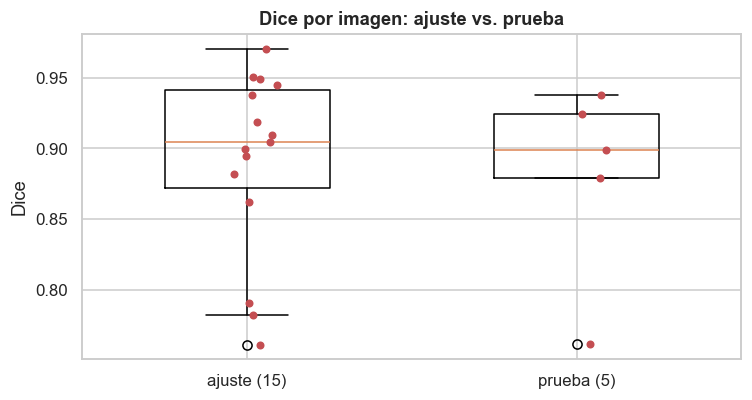

In [24]:
dice_ajuste = metricas_ajuste[(metricas_ajuste.beta == CONFIG_FINAL['beta']) & (metricas_ajuste.lam == CONFIG_FINAL['lam']) &
                              (metricas_ajuste.criterio == CONFIG_FINAL['criterio'])]
comparacion = pd.DataFrame({
    'Dice medio': [dice_ajuste.dice.mean(), metricas_prueba.loc[IDS_PRUEBA, 'Dice'].mean()],
    'Dice mediano': [dice_ajuste.dice.median(), metricas_prueba.loc[IDS_PRUEBA, 'Dice'].median()],
    'Dice mínimo': [dice_ajuste.dice.min(), metricas_prueba.loc[IDS_PRUEBA, 'Dice'].min()],
    'Dice máximo': [dice_ajuste.dice.max(), metricas_prueba.loc[IDS_PRUEBA, 'Dice'].max()],
    'V-measure medio': [dice_ajuste.vmeasure.mean(), metricas_prueba.loc[IDS_PRUEBA, 'V-measure'].mean()],
    'precisión media': [dice_ajuste.precision.mean(), metricas_prueba.loc[IDS_PRUEBA, 'precisión'].mean()],
    'recall medio': [dice_ajuste.recall.mean(), metricas_prueba.loc[IDS_PRUEBA, 'recall'].mean()],
}, index=['ajuste (15)', 'prueba (5)']).round(4)
display(comparacion)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.boxplot([dice_ajuste.dice, metricas_prueba.loc[IDS_PRUEBA, 'Dice']], labels=['ajuste (15)', 'prueba (5)'], widths=0.5)
for i, v in enumerate([dice_ajuste.dice.values, metricas_prueba.loc[IDS_PRUEBA, 'Dice'].values], start=1):
    ax.scatter(np.random.RandomState(0).normal(i, 0.04, len(v)), v, color='#c44e52', zorder=3, s=18)
ax.set_ylabel('Dice'); ax.set_title('Dice por imagen: ajuste vs. prueba'); plt.tight_layout(); plt.show()

> **Aciertos y errores en prueba** (configuración final sin cambios; Dice medio de prueba **0,8803**, frente a **0,8903** en ajuste).
>
> * **Aciertos:** ISIC_0000128 (Dice 0,938) y ISIC_0000105 (0,924) son lesiones oscuras y compactas sobre piel clara; la máscara casi coincide con la de referencia, aun con un punto rojo en 0105 que el criterio B descarta por no estar conectado. ISIC_0000123 (0,899) y ISIC_0000087 (0,879) también salen bien.
> * **Errores:** ISIC_0000110 es el peor caso (Dice 0,762; recall 0,615): lesión pálida y de bajo contraste con viñeteado; el método segmenta solo la parte más pigmentada y deja fuera la periferia que los dermatólogos incluyeron. En ISIC_0000123 la precisión baja a 0,847 (la única menor que 1 en prueba): el enrojecimiento de la piel alrededor de la lesión está lejos del color de piel del marco y se incluye como lesión. En 0087 el recall es 0,784 (parte de la lesión omitida).
> * **Patrón:** en prueba la precisión media es 0,969 y el recall medio 0,820; el método es conservador: casi no hay falsos positivos, pero subestima la extensión de la lesión.
> * No se esperaba un Dice alto en todas las imágenes, y no ocurre: el mínimo es 0,762 y el máximo 0,938.

<a name="s7"></a>
## 7. Análisis de resultados

Responder con apoyo en imágenes, tablas y valores concretos del notebook.

### 7.1 ¿Qué efecto tuvo incluir la posición de los píxeles? ¿En qué imágenes mejoró o perjudicó la segmentación y por qué?

**Con poco peso, el efecto es prácticamente nulo; con mucho peso, perjudica.** Con el criterio B, el Dice medio es 0,8878 (solo color), 0,8879 (λ/β = 0,05), 0,8872 (0,1), **0,8903 (0,25)**, 0,8844 (0,5), 0,8730 (0,75), 0,8285 (1), 0,7484 (2), 0,5941 (4) y 0,3549 (solo posición). La curva es plana hasta 0,5 y luego cae.

* **Mejoró en una imagen:** ISIC_0000094 (0,907 → 0,945 con λ/β = 0,25). Es una lesión pequeña y de bajo contraste; con la posición la silueta elige K = 5 y la lesión queda como un grupo compacto, sin los píxeles sueltos de la piel que aparecen con solo color. En las otras 14 imágenes la diferencia es menor a 0,002 en valor absoluto (ver gráfico): con λ/β pequeño la posición solo desempata los píxeles de frontera.
* **Perjudicó con λ/β ≥ 0,75:** la posición domina la distancia y K-medias empieza a partir la piel en bloques espaciales (K ≈ 5, silueta ≈ 0,44) sin relación con la lesión; con solo posición los grupos son cuatro cuadrantes idénticos en todas las imágenes (Dice 0,355 con B y 0,261 con A). La lesión rara vez coincide con un bloque espacial.
* **Por qué ayuda tan poco:** las lesiones están casi siempre al centro, pero eso no es información que K-medias aproveche en forma de distancia euclidiana; el color ya separa lesión y piel con K = 2. La posición sería más útil para lesiones de color parecido a la piel, justo el caso donde, en estas 15 imágenes, tampoco logra recuperar la periferia (0116, 0112, 0150: sin cambio).

,solo color (criterio B),config. final,diferencia
id,,,
ISIC_0000114,0.8835,0.8816,-0.0019
ISIC_0000133,0.8948,0.8942,-0.0006
ISIC_0000150,0.7908,0.7905,-0.0003
ISIC_0000085,0.9042,0.9042,0.0000
ISIC_0000086,0.9374,0.9374,0.0000
ISIC_0000137,0.9503,0.9503,0.0000
ISIC_0000153,0.9706,0.9706,0.0000
ISIC_0000156,0.9185,0.9185,0.0000
ISIC_0000157,0.8619,0.8619,0.0000


Imágenes donde la posición mejora (>0,005): 1 | empeora (<-0,005): 0 | sin cambio: 14


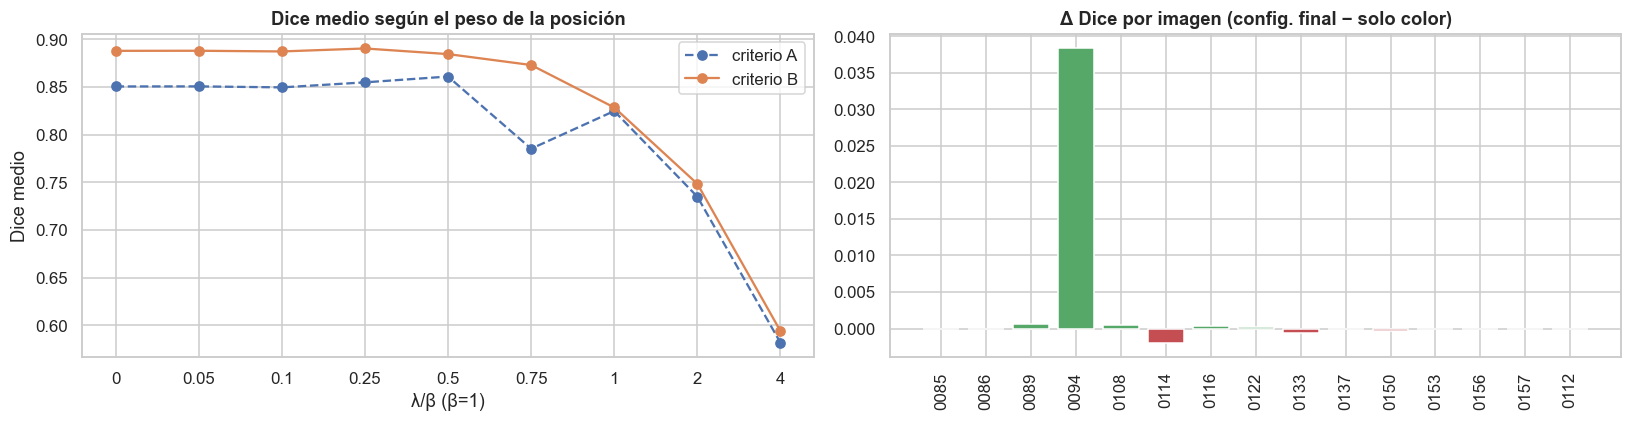

In [25]:
# Efecto de la posición: Dice por imagen con solo color frente a la configuración final
def dice_cfg(b, l, c):
    s = metricas_ajuste[(metricas_ajuste.beta == b) & (metricas_ajuste.lam == l) & (metricas_ajuste.criterio == c)]
    return s.set_index('id').dice

comp = pd.DataFrame({'solo color (criterio ' + CONFIG_FINAL['criterio'] + ')': dice_cfg(1, 0, CONFIG_FINAL['criterio']),
                     'config. final': dice_cfg(CONFIG_FINAL['beta'], CONFIG_FINAL['lam'], CONFIG_FINAL['criterio'])})
comp['diferencia'] = comp.iloc[:, 1] - comp.iloc[:, 0]
display(comp.round(4).sort_values('diferencia'))
print('Imágenes donde la posición mejora (>0,005):', (comp.diferencia > 0.005).sum(),
      '| empeora (<-0,005):', (comp.diferencia < -0.005).sum(), '| sin cambio:', (comp.diferencia.abs() <= 0.005).sum())

fig, axs = plt.subplots(1, 2, figsize=(15, 4))
for c, ls in zip('AB', ['--', '-']):
    s = (metricas_ajuste[(metricas_ajuste.criterio == c) & (metricas_ajuste.beta > 0) & (metricas_ajuste.lam >= 0)]
         .groupby('lam').dice.mean())
    axs[0].plot(range(len(s)), s.values, marker='o', ls=ls, label=f'criterio {c}')
axs[0].set_xticks(range(len(s))); axs[0].set_xticklabels([f'{v:g}' for v in s.index])
axs[0].set_xlabel('λ/β (β=1)'); axs[0].set_ylabel('Dice medio'); axs[0].set_title('Dice medio según el peso de la posición'); axs[0].legend()
axs[1].bar(range(len(comp)), comp.diferencia.values, color=np.where(comp.diferencia > 0, '#55a868', '#c44e52'))
axs[1].set_xticks(range(len(comp))); axs[1].set_xticklabels([i[-4:] for i in comp.index], rotation=90)
axs[1].set_title('Δ Dice por imagen (config. final − solo color)'); plt.tight_layout(); plt.show()

### 7.2 ¿Qué relación hay entre K, la silueta y el Dice? ¿Por qué estas métricas no necesariamente llevan a las mismas decisiones?

* **Relación débil.** Sobre las 15 imágenes y las combinaciones con color (criterio B), la correlación de Spearman con el Dice es **+0,449 para la silueta** y **−0,259 para K**. La silueta alta se asocia con Dice alto sobre todo porque K = 2 con color puro es lo más fácil de agrupar, pero dentro de ese grupo de siluetas altas (0,6–0,85) el Dice va de 0,76 a 0,97 (primer gráfico).
* **La silueta elige K = 2 en 14 de 15 imágenes** con la configuración final, pero el K que maximiza el Dice de cada imagen varía entre 2 y 6 y **coincide con el elegido por silueta solo en 1 de 15**. Si se fijara K = 5 en todas, el Dice medio sería ≈ 0,91 (gráfico), y con el mejor K por imagen (oráculo) 0,9275, frente a **0,8903** con la silueta: la silueta deja ≈ 0,04 de Dice sobre la mesa.
* **Por qué no coinciden.** La silueta mide qué tan compactos y separados están los grupos *entre sí*, sin saber qué es una lesión. K = 2 maximiza la separación (piel vs. zona pigmentada), pero tiende a subsegmentar: la lesión, con un gradiente de color desde el núcleo hasta la periferia, queda dividida entre grupos; con K mayor el criterio B puede reunir varios grupos (núcleo + transición) y recuperar la periferia que K = 2 deja fuera, aunque la silueta baje. El Dice, en cambio, compara contra el criterio de los dermatólogos.
* **V-measure** sigue otro camino: mide la correspondencia de todos los grupos con las dos clases, de modo que más grupos (aunque produzcan mejor máscara al unirse) lo penalizan; por eso la configuración final tiene V-measure 0,6155 y la de solo color 0,648 con Dice casi igual.

Correlación de Spearman con el Dice:
  silueta : 0.449
  K       : -0.259


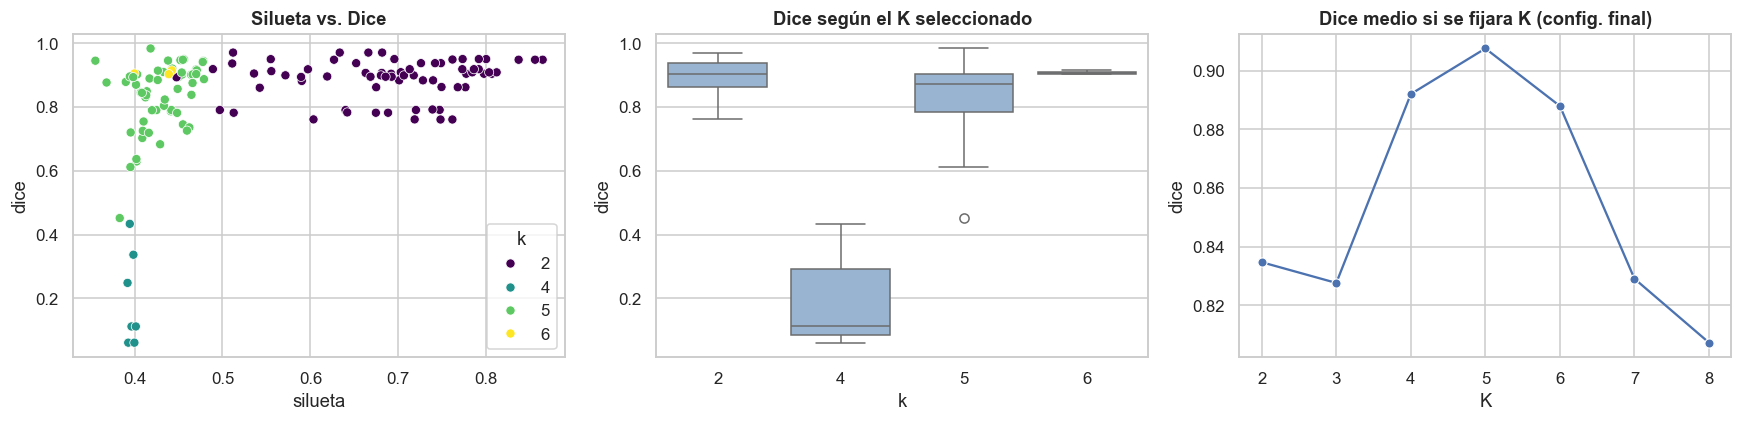

,K por silueta,Dice con K por silueta,K con mejor Dice,mejor Dice posible
ISIC_0000085,2,0.904,5,0.950
ISIC_0000086,2,0.937,5,0.975
ISIC_0000089,2,0.949,4,0.970
ISIC_0000094,5,0.945,4,0.945
ISIC_0000108,2,0.909,4,0.965
ISIC_0000114,2,0.882,2,0.882
ISIC_0000116,2,0.761,6,0.847
ISIC_0000122,2,0.899,6,0.914
ISIC_0000133,2,0.894,4,0.902
ISIC_0000137,2,0.950,6,0.990


Dice medio con K por silueta: 0.8903 | con el mejor K de cada imagen (oráculo): 0.9275 | coincide en 1 de 15 imágenes


In [26]:
# Relación entre K, silueta y Dice (todas las imágenes de ajuste × combinaciones con color, criterio final)
datos = metricas_ajuste[(metricas_ajuste.criterio == CONFIG_FINAL['criterio']) & (metricas_ajuste.beta > 0)]
print('Correlación de Spearman con el Dice:')
print('  silueta :', round(datos.silueta.corr(datos.dice, method='spearman'), 3))
print('  K       :', round(datos.k.corr(datos.dice, method='spearman'), 3))

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=datos, x='silueta', y='dice', hue='k', palette='viridis', ax=axs[0])
axs[0].set_title('Silueta vs. Dice')
sns.boxplot(data=datos, x='k', y='dice', color='#8fb4d9', ax=axs[1]); axs[1].set_title('Dice según el K seleccionado')

# Dice si se fijara K (mismos píxeles, β y λ finales, criterio final) frente al K elegido por silueta
filas = []
for _id in IDS_AJUSTE:
    r = AGRUPACIONES[(_id, CONFIG_FINAL['beta'], CONFIG_FINAL['lam'])]
    for k, et in r['etiquetas_por_k'].items():
        filas.append({'id': _id, 'K': k, 'dice': dice(mascaras[_id], CRITERIOS[CONFIG_FINAL['criterio']](imagenes[_id], et)),
                      'elegido': k == r['k']})
por_k = pd.DataFrame(filas)
sns.lineplot(data=por_k, x='K', y='dice', errorbar=None, marker='o', ax=axs[2])
axs[2].set_title('Dice medio si se fijara K (config. final)'); plt.tight_layout(); plt.show()

mejor_k = por_k.loc[por_k.groupby('id').dice.idxmax()].set_index('id')
cmp_k = pd.DataFrame({'K por silueta': [AGRUPACIONES[(i, CONFIG_FINAL['beta'], CONFIG_FINAL['lam'])]['k'] for i in IDS_AJUSTE],
                      'Dice con K por silueta': [por_k[(por_k.id == i) & por_k.elegido].dice.iloc[0] for i in IDS_AJUSTE],
                      'K con mejor Dice': [mejor_k.loc[i, 'K'] for i in IDS_AJUSTE],
                      'mejor Dice posible': [mejor_k.loc[i, 'dice'] for i in IDS_AJUSTE]}, index=IDS_AJUSTE)
display(cmp_k.round(3))
print('Dice medio con K por silueta:', round(cmp_k['Dice con K por silueta'].mean(), 4),
      '| con el mejor K de cada imagen (oráculo):', round(cmp_k['mejor Dice posible'].mean(), 4),
      '| coincide en', int((cmp_k['K por silueta'] == cmp_k['K con mejor Dice']).sum()), 'de 15 imágenes')

### 7.3 ¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué no se debe modificar el método tras consultar las máscaras de prueba?

| | Dice medio | Dice mín. | Dice máx. | V-measure | Precisión | Recall |
|:---|---:|---:|---:|---:|---:|---:|
| Ajuste (15) | 0,8903 | 0,761 | 0,971 | 0,6155 | 0,981 | 0,824 |
| Prueba (5) | 0,8803 | 0,762 | 0,938 | 0,6491 | 0,969 | 0,820 |

El Dice de prueba es 0,010 menor que el de ajuste, una diferencia mucho menor que la desviación entre imágenes (0,065) y que el error estándar con solo 5 imágenes (≈ 0,03): **no hay evidencia de sobreajuste**, y precisión y recall son casi iguales en ambos conjuntos. El método tiene pocos grados de libertad (β, λ, un umbral fijo y un criterio), y la selección se hizo entre solo 20 configuraciones separadas por centésimas, por lo que el sesgo optimista de elegir el máximo es pequeño. Aun así, 5 imágenes son una muestra muy limitada: este resultado indica consistencia, no garantiza desempeño en nuevas poblaciones.

**Por qué no modificar tras ver la prueba:** si se ajustaran β, λ, K o el criterio de máscara mirando las máscaras de prueba (por ejemplo, para «arreglar» ISIC_0000110), esas imágenes pasarían a ser de ajuste y el Dice de prueba dejaría de estimar el desempeño en imágenes nuevas: sería una estimación optimista por fuga de información. El valor de la prueba está en que solo se consulta una vez, al final.

### 7.4 Dos limitaciones del modelo y sus posibles causas (RGB + posición)

1. **Subsegmenta lesiones pálidas o con transición difusa (bajo recall).** Con precisión 0,98 y recall 0,82 en ajuste, los errores son sobre todo falsos negativos: ISIC_0000116, 0112 y 0150 tienen recall de 0,61–0,65 y en prueba ISIC_0000110 tiene 0,615. *Causa:* RGB solo describe el color del píxel, y la periferia de estas lesiones tiene un color muy cercano al de la piel; K-medias con distancia euclidiana la asigna al grupo de piel. Los dermatólogos, en cambio, trazan el borde usando textura, bordes y contexto, que esta representación no contiene (0150 incluso tiene un satélite y una zona despigmentada central).
2. **Sensibilidad a artefactos de iluminación y color.** El viñeteado oscuro (0133, 0112, 0110) crea un grupo de esquinas de color parecido a la lesión: el criterio A llega a Dice 0,596, y solo se corrige con la regla de conectividad del criterio B. El enrojecimiento perilesional (0123, precisión 0,847) y los puntos rojos (0105, 0156) también están lejos del color de piel. *Causa:* el método no distingue «oscuro por la lesión» de «oscuro por el instrumento» ni «rojo por la lesión» de «rojo por inflamación»; solo ve el valor RGB. La posición tampoco resuelve estos casos porque no aporta información de forma ni de bordes.

(Otras consecuencias de la representación: no hay información de textura, K es global a la imagen y no hay noción de objeto, y las imágenes se trabajaron a 96 px.)

### 7.5 Consecuencias de falsos positivos y falsos negativos en DermAlpes; sesgos y problemas de generalización

* **Falsos negativos (el caso dominante aquí).** La máscara queda más pequeña que la lesión y puede cortar bordes irregulares o zonas de transición, que son justamente parte de lo que el especialista evalúa (tamaño, forma, asimetría y borde). Una medición subestimada puede hacer parecer estable una lesión que creció o sugerir un contorno más regular de lo real. El riesgo de fondo: el especialista podría confiar en la máscara y mirar menos la región excluida. Con recall medio de 0,82, en promedio se omite casi 1 de cada 5 píxeles de lesión.
* **Falsos positivos.** La máscara incluye piel inflamada, viñeteado o marcas (como el enrojecimiento de 0123), sobrestima el tamaño y puede llevar a una medición equivocada o a derivar una consulta innecesaria. En estos datos son poco frecuentes (precisión 0,97), y su costo es menor porque el especialista siempre ve la imagen completa; pero si la medición se automatizara sin revisión, ambos errores se propagarían.
* **Sesgos y generalización.** (i) *Tono de piel:* el criterio depende de que la lesión sea más oscura o de color distinto al de la piel del marco; en pieles oscuras el contraste cae y la regla puede fallar, y los conjuntos públicos como éste suelen sobrerrepresentar pieles claras, así que no tenemos evidencia de cómo se comporta en otras poblaciones. (ii) *Lesiones no pigmentadas o rosadas* (amelanóticas) no cumplen la hipótesis «más oscura que la piel». (iii) *Condiciones de adquisición:* dermatoscopios y luz distintos cambian el color y el viñeteado; el vello, las reglas, el marcador quirúrgico y las burbujas de gel son artefactos no vistos. (iv) *Tamaño de muestra:* 15 imágenes de ajuste y 5 de prueba de una sola fuente son insuficientes para afirmar desempeño en producción; los parámetros se afinaron a esas imágenes. (v) *Variabilidad de las máscaras de referencia:* distintos especialistas trazan distinto el borde, así que parte del «error» es incertidumbre de la referencia.
* **Precauciones.** Usar la herramienta solo como apoyo visual (mostrar el contorno sobre la imagen original, no reemplazarla), no para diagnóstico ni medición sin revisión humana; validarla con imágenes propias de DermAlpes de distintos tonos de piel y dispositivos antes de desplegarla; y reportar métricas por subgrupo, no solo el promedio.

### Síntesis

Con solo K-medias sobre color (y un poco de posición) se obtiene un **Dice medio de 0,890 en ajuste y 0,880 en prueba**, con muy pocos falsos positivos y un recall cercano a 0,82. Lo que más pesó no fue la posición sino **el criterio de construcción de la máscara** (B frente a A: +0,037 de Dice medio y +0,165 en el peor caso con solo color) y la **selección de K**: la silueta elige K = 2 casi siempre, y se pierde ≈ 0,04 de Dice frente al mejor K por imagen. El método es una buena primera aproximación sin etiquetas, pero tiene limitaciones claras con lesiones pálidas, viñeteado y enrojecimiento, y exige validación con otras poblaciones antes de usarse con pacientes.

<a name="s8"></a>
## 8. Bonos

*Bonos opcionales (hasta 0,25 puntos cada uno). Se desarrollan ambos, A y B, sobre la configuración final (β = 1, λ = 0,25).*

### Bono A. Visualización del espacio de representación

Varianza explicada por PCA (2 componentes): [0.777 0.11 ] = 0.888


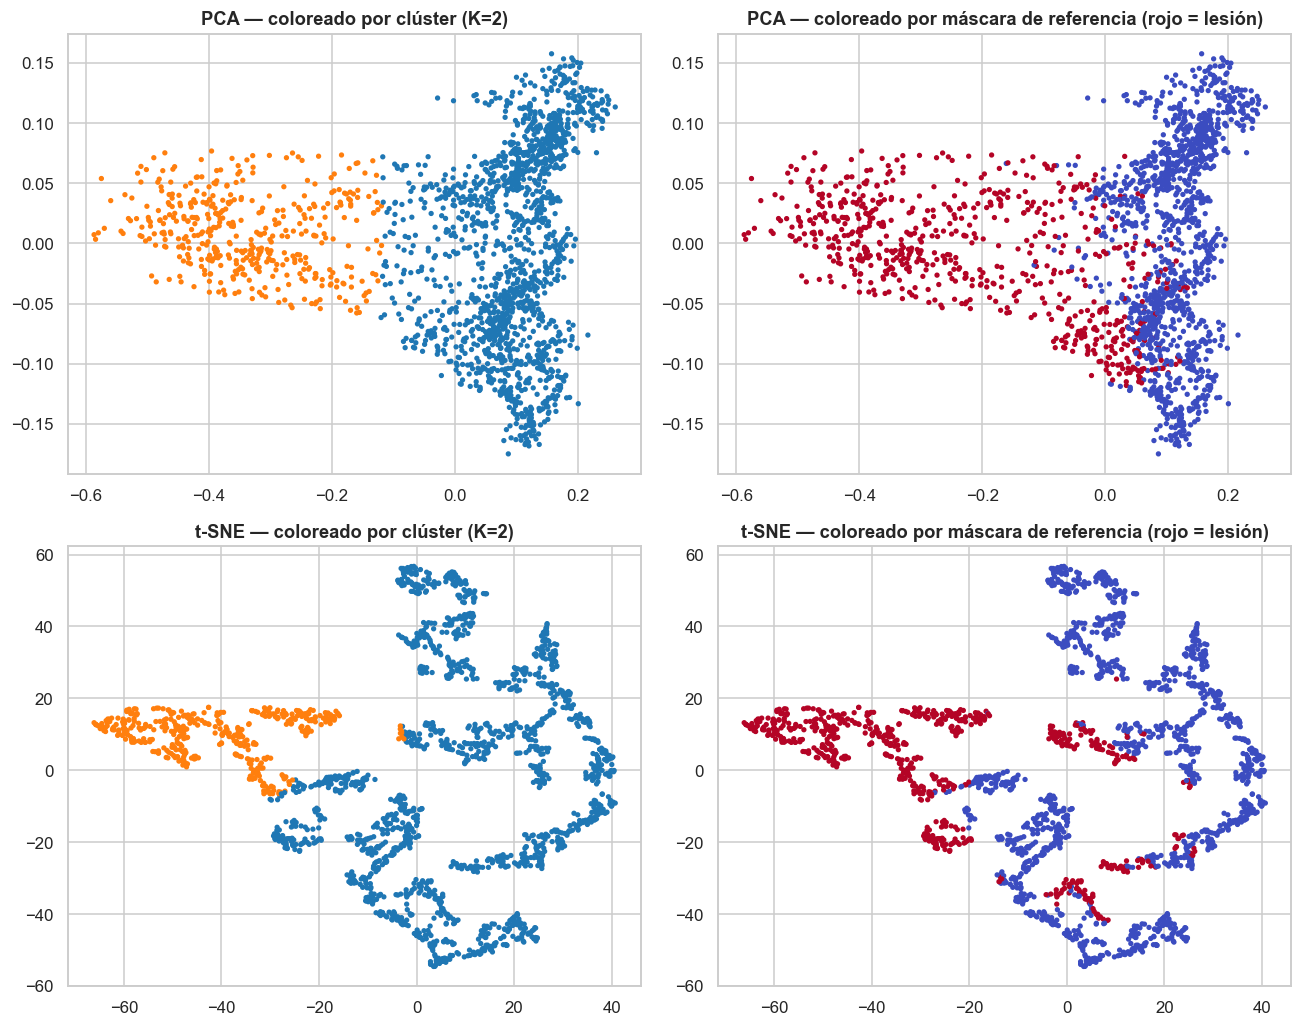

In [27]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

_id = 'ISIC_0000116'
img, ref = imagenes[_id], mascaras[_id]
r = AGRUPACIONES[(_id, CONFIG_FINAL['beta'], CONFIG_FINAL['lam'])]
X = RepresentacionPixel(CONFIG_FINAL['beta'], CONFIG_FINAL['lam']).transform(img)
idx = np.random.RandomState(RANDOM_STATE).choice(len(X), 2000, replace=False)
Xm, clu, ref_m = X[idx], r['etiquetas'].ravel()[idx], ref.ravel()[idx]

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(Xm)
T = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE).fit_transform(Xm)
print('Varianza explicada por PCA (2 componentes):', pca.explained_variance_ratio_.round(3), '=', pca.explained_variance_ratio_.sum().round(3))

fig, axs = plt.subplots(2, 2, figsize=(12, 9.5))
for fila, (Z, nombre) in enumerate([(P, 'PCA'), (T, 't-SNE')]):
    axs[fila, 0].scatter(Z[:, 0], Z[:, 1], c=clu, cmap='tab10', s=6, vmin=0, vmax=9); axs[fila, 0].set_title(f'{nombre} — coloreado por clúster (K={r["k"]})')
    axs[fila, 1].scatter(Z[:, 0], Z[:, 1], c=ref_m, cmap='coolwarm', s=6); axs[fila, 1].set_title(f'{nombre} — coloreado por máscara de referencia (rojo = lesión)')
plt.tight_layout(); plt.show()

> **Interpretación (imagen ISIC_0000116; muestra aleatoria de 2 000 píxeles, representación [β·R, β·G, β·B, λ·x, λ·y] de la configuración final).**
> * **Coincidencias:** en PCA, las dos primeras componentes explican el 88,8 % de la varianza (PC1: 77,7 %, que corresponde sobre todo al brillo/color). El clúster naranja (K = 2) ocupa el extremo izquierdo de PC1, donde casi todos los puntos de la máscara de referencia (rojo) están; en t-SNE ese grupo también forma una región separada. Esto confirma que el color separa la lesión de la piel.
> * **Diferencias:** los puntos rojos de la referencia se extienden hacia la masa azul (periferia de la lesión con color parecido a la piel), y el clúster los deja en el grupo de piel: es la causa de los falsos negativos (recall ≈ 0,61 en esta imagen). En t-SNE aparecen además pequeñas islas rojas dentro de la región de piel.
> * **Estructura de «brazos»:** la piel forma filamentos largos tanto en PCA (hacia arriba y abajo en PC2) como en t-SNE; refleja la variación continua de las coordenadas x, y (y del gradiente de iluminación), no subgrupos reales.
> * **Limitaciones de la proyección:** PCA es lineal y pierde el 11 % de la varianza; en t-SNE solo la vecindad local es fiable, y las distancias entre regiones, su tamaño relativo y los espacios vacíos no son interpretables; además depende de la semilla y la perplejidad, y se usó una muestra del total de píxeles. Ninguna proyección sustituye a las métricas de la sección 5.

### Bono B. Investigación y comparación con mean shift

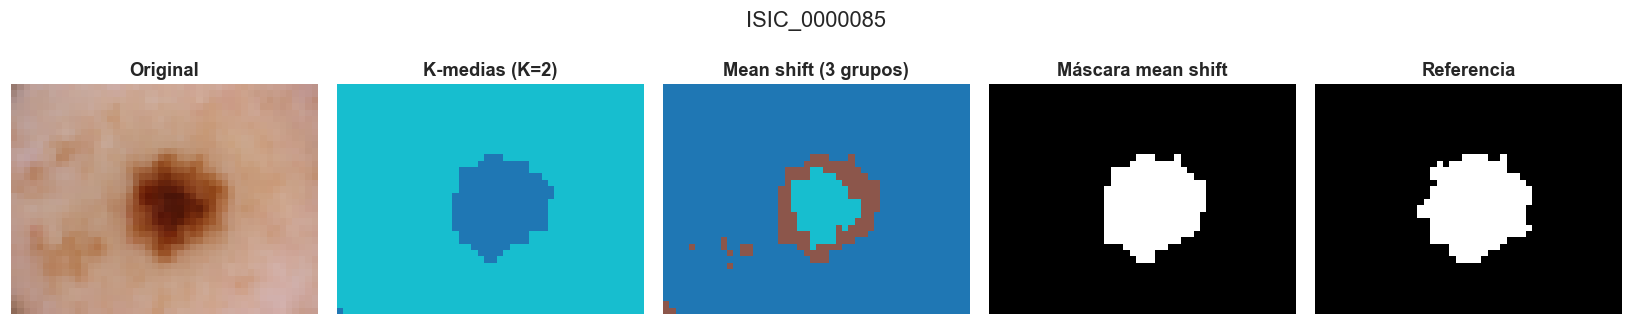

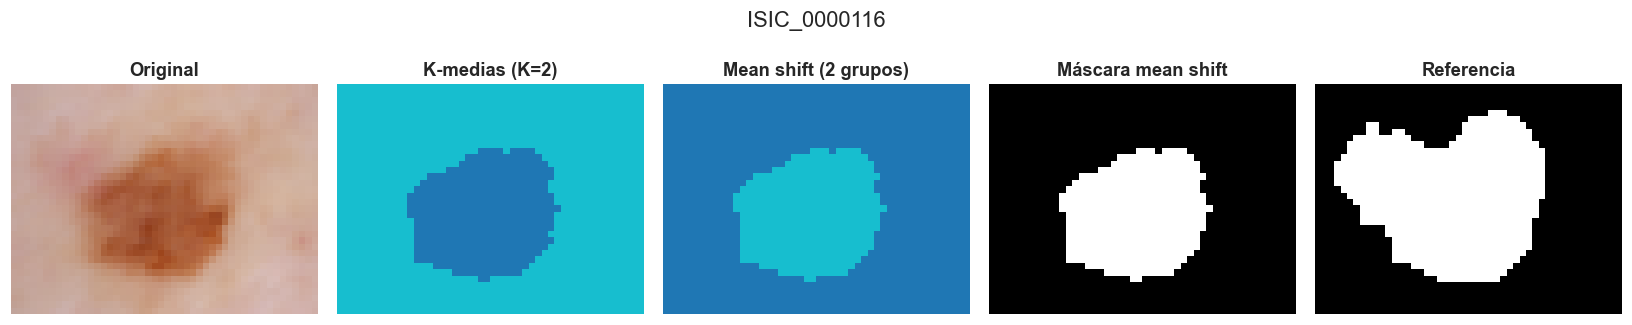

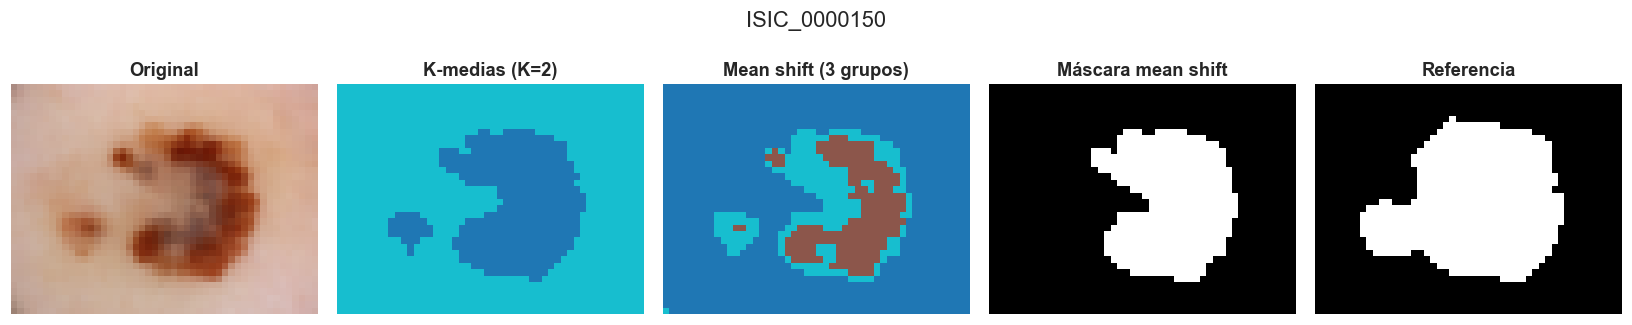

,Dice K-medias,K (silueta),t K-medias (s),Dice mean shift,grupos mean shift,ancho de banda,t mean shift (s)
id,,,,,,,
ISIC_0000085,0.938,2,1.482,0.954,3,0.159,0.688
ISIC_0000116,0.756,2,1.512,0.751,2,0.150,0.652
ISIC_0000150,0.801,2,1.551,0.828,3,0.182,0.781


In [28]:
from sklearn.cluster import MeanShift, estimate_bandwidth

def reducir(_id, lado=48):
    im, mk, _ = cargar_par(_id, tamano=lado)
    return im, mk

filas = []
for _id in ['ISIC_0000085', 'ISIC_0000116', 'ISIC_0000150']:
    im, mk = reducir(_id)
    X = RepresentacionPixel(CONFIG_FINAL['beta'], CONFIG_FINAL['lam']).transform(im)
    # K-medias con K elegido por silueta en esta misma resolución
    t = time.time(); rk = seleccionar_k(im, CONFIG_FINAL['beta'], CONFIG_FINAL['lam']); t_km = time.time() - t
    est_km, m_km = evaluar(im, mk, rk['etiquetas'], CONFIG_FINAL['criterio'])
    # Mean shift
    t = time.time()
    bw = estimate_bandwidth(X, quantile=0.2, n_samples=500, random_state=RANDOM_STATE)
    ms = MeanShift(bandwidth=bw, bin_seeding=True).fit(X)
    t_ms = time.time() - t
    et_ms = ms.labels_.reshape(mk.shape)
    est_ms = CRITERIOS[CONFIG_FINAL['criterio']](im, et_ms)
    filas.append({'id': _id, 'Dice K-medias': m_km['dice'], 'K (silueta)': rk['k'], 't K-medias (s)': t_km,
                  'Dice mean shift': dice(mk, est_ms), 'grupos mean shift': len(np.unique(et_ms)),
                  'ancho de banda': bw, 't mean shift (s)': t_ms})
    fig, axs = plt.subplots(1, 5, figsize=(15, 3.2))
    for ax, d, t_ in zip(axs, [im, rk['etiquetas'], et_ms, est_ms, mk],
                         ['Original', f"K-medias (K={rk['k']})", f"Mean shift ({len(np.unique(et_ms))} grupos)", 'Máscara mean shift', 'Referencia']):
        ax.imshow(d, cmap='tab10' if 'grupos' in t_ or 'K-medias' in t_ else 'gray'); ax.set_title(t_); ax.axis('off')
    plt.suptitle(_id); plt.tight_layout(); plt.show()
pd.DataFrame(filas).set_index('id').round(3)

> **Cómo funciona el ancho de banda.** Mean shift trata los píxeles como una nube de puntos en el espacio de 5 dimensiones y estima su densidad con un núcleo; cada punto se desplaza iterativamente hacia el promedio de los puntos que están a una distancia menor que el **ancho de banda** *h*, hasta converger a un máximo local de densidad (una «moda»). Los puntos que convergen a la misma moda forman un grupo. *h* es el radio de la vecindad: con *h* pequeño hay muchas modas y muchos grupos; con *h* grande se fusionan y quedan pocos. Aquí se estimó con `estimate_bandwidth(quantile=0,2)` (≈ 0,15–0,18 en espacio normalizado).
>
> **Por qué no requiere fijar K.** El número de grupos no es un parámetro: es el número de modas de la densidad, que depende de los datos y de *h*. El costo es que *h* pasa a ser el hiperparámetro crítico, y que se pierde el control directo sobre el número de grupos.
>
> **Comparación** (imágenes reducidas a lado mayor = 48 px para que mean shift sea ejecutable, ya que su costo crece aproximadamente con el cuadrado del número de píxeles; se aplicó el criterio B a ambos métodos). El Dice es parecido: 0,954 vs. 0,938 en ISIC_0000085, 0,751 vs. 0,756 en 0116 y 0,828 vs. 0,801 en 0150 (mean shift / K-medias). Mean shift encontró 2–3 grupos sin que se le indicara K. Los tiempos (≈ 0,7 s frente a ≈ 1,5 s) **no son comparables en justicia**: el tiempo de K-medias incluye ajustar 7 valores de K y calcular la silueta, mientras que mean shift se ajusta una sola vez con *h* fijo; a mayor resolución mean shift se vuelve mucho más lento (por eso no se aplicó a 96 px ni a las 15 imágenes). No se repite el protocolo completo, como indica el enunciado; con 3 imágenes no hay evidencia de que uno sea mejor que otro.

<a name="s9"></a>
## 9. Uso de herramientas de IA generativa

*Sección obligatoria según los principios del curso ISIS-2611 publicados en Bloque Neón.*

### 9.1 Declaración del uso

| Herramienta | Tipo de uso |
|:---|:---|
| Claude (Anthropic), mediante Claude Code en VS Code | Generación inicial del esqueleto del notebook (estructura de secciones y celdas con `# TODO`). |
| TODO: herramienta usada en la actividad de verificación | Consulta previa de valores de β, λ y K y de un criterio para construir la máscara (ver 9.3). |
| TODO: otros usos (depuración, redacción, ayuda conceptual) | TODO |

### 9.2 Prompt para generar el esqueleto del notebook (textual)

> Actúa como un experto en Ciencia de Datos y Aprendizaje Automático. Necesito que generes ÚNICAMENTE un archivo de Jupyter Notebook (.ipynb) que sirva como esqueleto/plantilla estructurada para resolver el "Laboratorio 4 - Segmentación de imágenes con técnicas de agrupación" del curso ISIS2611.
>
> INSTRUCCIONES CLAVE DE FORMATO Y CONTENIDO:
> 1. NO escribas código funcional completo para la segmentación ni el análisis; genera el ESQUELETO DEL NOTEBOOK con celdas de Markdown explicativas y celdas de código con el boilerplate, librerías importadas, nombres de funciones, comentarios `# TODO:` y la estructura paso a paso para completar el laboratorio.
> 2. Organiza el notebook en secciones claras con títulos en Markdown (`#`, `##`, `###`), siguiendo estrictamente la rúbrica y las actividades del enunciado.
> 3. Todo el esqueleto (títulos, explicaciones, comentarios y nombres) debe estar en español.
> 4. Usa como guía de estructura los archivos del Laboratorio 3 (portada con decisiones metodológicas, contenido enlazado, secciones numeradas, sección final de IA generativa).
>
> ESTRUCTURA DEL NOTEBOOK A GENERAR: encabezado con integrantes y contexto del caso DermAlpes; 1. Configuración del entorno, citación de la fuente (ISIC 2016) y carga de las 15 imágenes de ajuste y 5 de prueba con sus máscaras (conversión de 255 a 1 y redimensionamiento por vecino más cercano); 2. Pipeline de scikit-learn que represente cada píxel como [β·R, β·G, β·B, λ·x, λ·y] normalizado en [0, 1], con β y λ como parámetros; 3. K-medias con K entre 2 y 8, diez combinaciones de β y λ (incluyendo solo color y solo posición) y selección de K con el coeficiente de silueta sobre una muestra reproducible de píxeles (documentar tamaño y semilla); 4. Criterios automáticos para identificar los grupos de la lesión y construir la máscara binaria; 5. Ajuste con las 15 imágenes de ajuste usando Dice (criterio principal) y V-measure (complementario), visualizaciones de las dos mejores configuraciones y de solo color y solo posición, y revisión de casos de fallo; 6. Evaluación en las 5 imágenes de prueba sin modificar el método, con tabla de K, silueta, Dice, V-measure, precisión y recall, e imágenes original/estimada/referencia; 7. Análisis de resultados con las cinco preguntas del enunciado; 8. Bonos opcionales (PCA/t-SNE y mean shift); 9. Uso de herramientas de IA generativa (declaración, prompts, análisis crítico, aportes propios y actividad de verificación). Genera directamente el archivo `.ipynb` limpio y bien estructurado en el directorio actual.

### 9.3 Actividad de verificación (obligatoria)

Antes de elegir la configuración final, se consultó a una herramienta de IAG por valores de β, λ y K y por un criterio para identificar los grupos de la lesión. Según el enunciado, la consulta **no anexó imágenes ni mencionó el nombre del conjunto (ISIC)**: solo describió las imágenes.

**Prompt utilizado (en español):**

> Estoy segmentando imágenes dermatoscópicas de lesiones de piel (fotografías a color de la piel tomadas con un dermatoscopio, donde la lesión suele ser una mancha más oscura o de color distinto al de la piel circundante, ocupa una parte central de la imagen y puede haber vello, burbujas o viñeteado en los bordes) usando K-medias, sin ningún entrenamiento supervisado. Cada píxel se representa con el vector [β·R, β·G, β·B, λ·x, λ·y], con color y coordenadas normalizados entre 0 y 1, donde β pondera el color y λ la posición. Quiero que me recomiendes: (1) valores concretos de β y λ (o la razón λ/β); (2) el rango y el valor de K, y cómo elegirlo con el coeficiente de silueta; y (3) un criterio automático, que no use máscaras de referencia, para decidir cuáles grupos corresponden a la lesión y construir una máscara binaria. Justifica cada recomendación.

**Historial de la conversación:** TODO: adjuntar el historial completo (prompt, respuesta y sucesivas interacciones), por ejemplo como texto, enlace o archivo anexo.

**Resumen de la recomendación recibida:** TODO.

**Prueba de la recomendación con las imágenes de ajuste:** TODO (incluir el Dice promedio obtenido con los valores sugeridos frente a la configuración final).

In [ ]:
# Prueba de la recomendación de la IAG sobre las 15 imágenes de ajuste.
# Recomendación: β = 1, λ = 0,2 (λ/β = 0,2); K ∈ {2, 3, 4, 5} elegido por silueta;
# lesión = grupo cuyo color medio está más lejos del color de piel del marco, conservando la componente
# conexa más cercana al centro (con huecos rellenos).
REC = {'beta': 1.0, 'lam': 0.2, 'k_rango': range(2, 6)}

def mascara_recomendada(img, etiquetas):
    x = img.reshape(-1, 3).astype(float)
    dist = np.linalg.norm(x - _color_piel(img), axis=1)
    lab = etiquetas.ravel()
    ks = np.unique(lab)
    k_les = ks[np.argmax([dist[lab == k].mean() for k in ks])]
    comp, n = ndi.label(etiquetas == k_les)
    if n == 0:
        return (etiquetas == k_les).astype(np.uint8)
    h, w = etiquetas.shape
    centros = ndi.center_of_mass(np.ones_like(comp), comp, range(1, n + 1))
    d_centro = [np.hypot(cy - h / 2, cx - w / 2) for cy, cx in centros]
    return ndi.binary_fill_holes(comp == 1 + int(np.argmin(d_centro))).astype(np.uint8)

filas = []
for _id in IDS_AJUSTE:
    r = seleccionar_k(imagenes[_id], REC['beta'], REC['lam'], k_rango=REC['k_rango'])
    est = mascara_recomendada(imagenes[_id], r['etiquetas'])
    y, p = mascaras[_id].ravel(), est.ravel()
    filas.append({'id': _id, 'K (silueta, 2-5)': r['k'], 'silueta': r['sil'], 'Dice': dice(mascaras[_id], est),
                  'precisión': precision_score(y, p, zero_division=0), 'recall': recall_score(y, p, zero_division=0)})
rec_ajuste = pd.DataFrame(filas).set_index('id')
final_ajuste = dice_cfg(CONFIG_FINAL['beta'], CONFIG_FINAL['lam'], CONFIG_FINAL['criterio'])
rec_ajuste['Dice config. final'] = final_ajuste
rec_ajuste['Δ Dice (IAG − final)'] = rec_ajuste['Dice'] - rec_ajuste['Dice config. final']
display(rec_ajuste.round(3))

print(f"Dice medio con la recomendación de la IAG : {rec_ajuste['Dice'].mean():.4f} (mín. {rec_ajuste['Dice'].min():.3f})")
print(f"Dice medio con la configuración final      : {final_ajuste.mean():.4f} (mín. {final_ajuste.min():.3f})")
print('Imágenes donde la IAG supera a la config. final:', int((rec_ajuste['Δ Dice (IAG − final)'] > 0.005).sum()),
      '| empeora:', int((rec_ajuste['Δ Dice (IAG − final)'] < -0.005).sum()),
      '| sin cambio:', int((rec_ajuste['Δ Dice (IAG − final)'].abs() <= 0.005).sum()))

peores_rec = rec_ajuste['Dice'].nsmallest(3).index
fig, axs = plt.subplots(len(peores_rec), 4, figsize=(13, 3.3 * len(peores_rec)))
for fila, _id in enumerate(peores_rec):
    r = seleccionar_k(imagenes[_id], REC['beta'], REC['lam'], k_rango=REC['k_rango'])
    est = mascara_recomendada(imagenes[_id], r['etiquetas'])
    axs[fila, 0].imshow(imagenes[_id]); axs[fila, 0].set_title(_id)
    axs[fila, 1].imshow(r['etiquetas'], cmap='tab10', vmin=0, vmax=9); axs[fila, 1].set_title(f"Grupos IAG (K={r['k']})")
    axs[fila, 2].imshow(est, cmap='gray'); axs[fila, 2].set_title(f"Máscara IAG (Dice={rec_ajuste.loc[_id, 'Dice']:.2f})")
    axs[fila, 3].imshow(mascaras[_id], cmap='gray'); axs[fila, 3].set_title('Referencia')
for ax in axs.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()


**Respuestas a las preguntas de verificación:**

* **¿La recomendación funcionó en nuestras imágenes?** TODO
* **¿En qué acertó y en qué falló?** TODO
* **¿Por qué la IAG no podía anticipar el comportamiento del método en nuestras imágenes?** TODO

### 9.4 Análisis crítico del resultado

*(Responder al menos dos.)*

* **¿Qué partes del contenido generado fueron correctas y útiles?** TODO
* **¿Qué errores, imprecisiones o limitaciones se identificaron?** TODO
* **¿Qué decisiones técnicas fueron modificadas respecto a la respuesta de la IAG y por qué?** TODO
* **¿Qué conceptos del curso permitieron evaluar o mejorar la respuesta generada?** TODO

### 9.5 Aportes propios del estudiante

* **¿Qué fue desarrollado, modificado o decidido por el estudiante?** TODO
* **¿Qué ajustes se realizaron sobre el código o la explicación original?** TODO
* **¿Qué aprendizajes se obtuvieron del proceso?** TODO

---

## Conclusiones

TODO: resumir los hallazgos principales (configuración final, Dice de ajuste vs. prueba, limitaciones y precauciones para DermAlpes).